# 3. Local projections of MATIF new-crop returns on the Rostov frost-kill signal

This notebook tests whether a frost-kill day in Rostov Oblast moves Euronext milling wheat (MATIF) futures. It produces paper Figures 4 and 5 and the numbers quoted in paper sections 2.4 and 3. Robustness checks that are not in the paper follow in section 3.

## Contract matching

A frost in February of year Y damages wheat sown in autumn Y−1 and harvested in summer Y. The nearby contract in February is March Y, which delivers grain from the Y−1 harvest that is already in store. Each frost winter is therefore matched to the first contract that delivers the damaged harvest, following McKenzie (2008).

Euronext changed the delivery cycle in 2015. Contract months were November, January, March and May until May 2015, and September, December, March and May from September 2015 onward.

| Frost winter | Harvest | Contract |
|---|---|---|
| 2005/06 to 2013/14 | 2006 to 2014 | `MLX06` to `MLX14` |
| 2014/15 to 2025/26 | 2015 to 2026 | `MLU15` to `MLU26` |

## Sample start

Barchart's expired-contract history for the ML root begins on 13 July 2005. A download of `MLX06` over 1 October 2004 to 31 July 2005 returns only 13 rows, all between 13 and 29 July 2005, with open interest already at 27,213 on the first day. `MLX05` and `MLX04` fall almost entirely before that date, so `MLX06` is the first fully covered contract and the 2001/02 to 2004/05 winters are lost.

## Data validation

When a symbol lookup fails, Barchart's download page stays on the previous contract and serves it under the new file name. Section 1 therefore checks every file against its expected date window and hashes each price series to catch duplicates.

## Returns

Every observation is `p(t+h) − p(t−1)` for h from −12 to +30, computed within one contract. Windows run from 1 October to 31 July and consecutive windows start twelve months apart, so they never overlap. Nothing is differenced across contracts, so no roll adjustment is needed.

Run from the repository root. The 21 contract files are not part of the repository (see the README).

## 1. Data

The 21 contract files are validated against their expected windows, stacked into one panel and joined to the Rostov signal. Kill that falls on a weekend or holiday is rolled onto the next trading session.

In [1]:
import sys, re, warnings, hashlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
warnings.filterwarnings("ignore")

ROOT      = Path.cwd()                                    # run from the repository root
CONTRACTS = ROOT / "data" / "futures_prices"              # 21 Barchart contract CSVs, not in the repo
NEARBY    = sorted((CONTRACTS / "nearby").glob("*.csv"))  # continuous nearby series, old-crop check
SIGNAL    = ROOT / "output" / "oblast_signal" / "frostol_oblast_rostov_daily.csv"
OUT       = ROOT / "output" / "tables"
FIGDIR    = ROOT / "output" / "figures"
for p in (OUT, FIGDIR): p.mkdir(parents=True, exist_ok=True)

H_FWD, H_PRE, LAGS, ALPHA = 30, 12, 5, 0.05
FROST_MONTHS = [11,12,1,2,3,4]
assert H_PRE > LAGS + 1, "placebo degenerate otherwise"

WIN_START_MD, WIN_END_MD = (10,1), (7,31)   # Oct 1 of harvest_year-1 -> Jul 31
MIN_VOL      = 1        # a day needs at least this volume to count as traded
MAX_STALE    = 3        # flag runs of >= this many zero-change days
print("contract files:", len(list(CONTRACTS.glob("*.csv"))), "| nearby files:", len(NEARBY))

contract files: 21 | nearby files: 1


In [2]:
# --- Load the contract files and validate them ------------------------------------
MONTH = {"X": 11, "U": 9}     # X = November (pre-2015), U = September (post-2015)

def parse_symbol(path):
    m = re.match(r"^(ml)([xu])(\d{2})", path.name.lower())
    if not m: return None
    code, yy = m.group(2).upper(), int(m.group(3))
    hy = 2000 + yy                       # Nov Y and Sep Y both deliver harvest Y
    return dict(symbol=f"ML{code}{yy:02d}", month=MONTH[code], harvest_year=hy,
                frost_season=f"{hy-1}/{str(hy)[2:]}",
                win0=pd.Timestamp(hy-1, *WIN_START_MD),
                win1=pd.Timestamp(hy,   *WIN_END_MD))

def read_barchart_contract(path):
    d = pd.read_csv(path, skipfooter=1, engine="python")
    d = d.rename(columns={c: c.strip() for c in d.columns})
    tcol = next(c for c in ["Time","Date","date"] if c in d.columns)
    pcol = next(c for c in ["Latest","Last","Close","Settle"] if c in d.columns)
    out = pd.DataFrame({"date": pd.to_datetime(d[tcol], errors="coerce"),
                        "px": pd.to_numeric(d[pcol], errors="coerce")})
    for src, dst in [("Volume","volume"), ("Open Int","oi"), ("Open Interest","oi")]:
        if src in d.columns:
            out[dst] = pd.to_numeric(d[src].astype(str).str.replace(",",""), errors="coerce")
    return out.dropna(subset=["date","px"]).sort_values("date").reset_index(drop=True)

files = sorted(CONTRACTS.glob("*.csv"))
assert files, f"no CSVs in {CONTRACTS}"
rows, panels, hashes = [], [], {}
for f in files:
    meta = parse_symbol(f)
    if meta is None:
        print(f"  SKIP unparseable filename: {f.name}"); continue
    d = read_barchart_contract(f)
    if d.empty:
        rows.append(dict(**{k: meta[k] for k in ("symbol","frost_season")},
                         n=0, flag="EMPTY")); continue
    inwin = d[(d.date >= meta["win0"]) & (d.date <= meta["win1"])]
    h = hashlib.md5(np.round(d.px.values, 4).tobytes()).hexdigest()[:10]
    flags = []
    if h in hashes: flags.append(f"DUPLICATE of {hashes[h]}")
    hashes.setdefault(h, meta["symbol"])
    frac = len(inwin) / max(len(d), 1)
    if frac < 0.90: flags.append(f"only {frac:.0%} of rows inside window")
    if len(inwin) < 100: flags.append(f"only {len(inwin)} rows in window")
    if "volume" not in d.columns: flags.append("NO VOLUME COLUMN")
    rows.append(dict(symbol=meta["symbol"], frost_season=meta["frost_season"],
                     n=len(inwin), first=inwin.date.min(), last=inwin.date.max(),
                     med_vol=inwin.volume.median() if "volume" in inwin else np.nan,
                     zero_vol_days=int((inwin.volume < MIN_VOL).sum()) if "volume" in inwin else -1,
                     flag="; ".join(flags) if flags else "ok"))
    if inwin.empty: continue
    q = inwin.copy()
    for k in ("symbol","frost_season","harvest_year"): q[k] = meta[k]
    panels.append(q)

val = pd.DataFrame(rows)
print(val.to_string(index=False))
bad = val[val.flag != "ok"]
print(f"\n{len(val)} files | {len(bad)} flagged")
if len(bad):
    print("\nFLAGGED -- inspect before using:")
    print(bad[["symbol","frost_season","n","flag"]].to_string(index=False))
    print("\nA DUPLICATE means Barchart served the same contract twice: the symbol")
    print("lookup silently failed and the page never navigated. Re-download that one.")
val.to_csv(OUT / "newcrop_contract_validation.csv", index=False)

symbol frost_season   n      first       last  med_vol  zero_vol_days flag
 MLU15      2014/15 212 2014-10-01 2015-07-31  34995.5              0   ok
 MLU16      2015/16 212 2015-10-01 2016-07-29  35081.5              0   ok
 MLU17      2016/17 212 2016-10-03 2017-07-31  31479.5              0   ok
 MLU18      2017/18 211 2017-10-02 2018-07-31  35303.0              0   ok
 MLU19      2018/19 212 2018-10-01 2019-07-31  35384.0              0   ok
 MLU20      2019/20 213 2019-10-01 2020-07-31  43905.0              0   ok
 MLU21      2020/21 213 2020-10-01 2021-07-30  54482.0              0   ok
 MLU22      2021/22 214 2021-10-01 2022-07-29  54263.0              0   ok
 MLU23      2022/23 212 2022-10-03 2023-07-31  55430.5              0   ok
 MLU24      2023/24 212 2023-10-02 2024-07-31  78986.0              0   ok
 MLU25      2024/25 212 2024-10-01 2025-07-31  86698.5              1   ok
 MLU26      2025/26 212 2025-10-01 2026-07-31  91882.0              3   ok
 MLX06      2005/06 212 2

In [3]:
# --- Build the panel: returns within contract, signal rolled to trading days ------
# Kill that lands on a weekend or holiday is rolled onto the next trading session, so it
# is not discarded. kill_incr is a within-season difference, so its sum over closed days
# is the change in cumulative kill between settlements.
pan = pd.concat(panels, ignore_index=True).sort_values(["symbol","date"])
pan["logp"] = np.log(pan.px)
g = pan.groupby("symbol", sort=False)
pan["ret"] = g["logp"].diff()

# staleness: runs of identical settlement with no volume = interpolated settlements
pan["nochange"] = (pan.ret.abs() < 1e-12).fillna(False)
run = pan.groupby("symbol")["nochange"].transform(
        lambda s: s.groupby((~s).cumsum()).cumsum())
pan["stale"] = (run >= MAX_STALE) & (pan.get("volume", pd.Series(1, index=pan.index)) < MIN_VOL)

# overlap check: windows must not collide
ov = pan.groupby("date")["symbol"].nunique()
print("dates covered by >1 contract:", int((ov > 1).sum()), "(must be 0)")
print(f"panel: {pan.symbol.nunique()} contracts, {len(pan):,} rows, "
      f"{pan.date.min().date()} -> {pan.date.max().date()}")
print(f"stale rows flagged: {int(pan.stale.sum())} ({pan.stale.mean():.1%})")

sig   = pd.read_csv(SIGNAL, parse_dates=["date"]).sort_values("date")
tdays = pd.DatetimeIndex(sorted(pan.date.unique()))

# where the raw signal fires relative to the trading calendar
cal = sig[(sig.kill_incr > 0) & sig.date.dt.month.isin(FROST_MONTHS)].copy()
cal["cat"] = np.where(cal.date.isin(tdays), "trading day",
              np.where(cal.date < tdays.min(), "before price sample",
               np.where(cal.date.dt.dayofweek >= 5, "weekend", "weekday holiday")))
print("\nin-window firing days by calendar status:")
print(cal.groupby("cat").agg(days=("date","size"), kill=("kill_incr","sum")).round(3).to_string())

# roll every calendar day onto the next trading session
sg = sig.set_index("date").loc[tdays.min():tdays.max()].copy()
sg["kill_incr"] = sg["kill_incr"].fillna(0.0)
if "coverage_ok" in sg: sg["coverage_ok"] = sg["coverage_ok"].astype(bool)
nxt = pd.Series(tdays, index=tdays).reindex(sg.index, method="bfill")
ok  = nxt.notna(); sg, nxt = sg[ok], nxt[ok]

how = {"kill_incr": "sum"}
if "RF_FROST_T"  in sg: how["RF_FROST_T"]  = "last"
if "coverage_ok" in sg: how["coverage_ok"] = "all"
rolled = sg.groupby(nxt).agg(how)
rolled.index.name = "date"
assert abs(rolled.kill_incr.sum() - sg.kill_incr.sum()) < 1e-9, "kill mass lost in the roll"

df = pan.merge(rolled.reset_index(), on="date", how="left")
df["kill_incr"] = df["kill_incr"].fillna(0.0)
if "coverage_ok" in df:
    df.loc[df.coverage_ok.eq(False), "kill_incr"] = np.nan
df.loc[df.stale, "kill_incr"] = np.nan          # no usable price -> no observation
df["shock"] = (df.kill_incr > 0).astype(float)
df.loc[df.kill_incr.isna(), "shock"] = np.nan
df = df.set_index("date").sort_index()

win = df.index.month.isin(FROST_MONTHS)
print(f"\nfrost days, all months : {int(sig.loc[sig.kill_incr > 0, 'date'].isin(tdays).sum())}"
      f" -> {int(df.shock.sum())}")
print(f"frost days, Nov-Apr    : {int(cal.date.isin(tdays).sum())}"
      f" -> {int(df.loc[win, 'shock'].sum())}   <- the LP event count")

ev = df[df.shock > 0]
print(f"\nfrost days in panel: {int(df.shock.sum())} across "
      f"{ev.frost_season.nunique()} crop years")
print("crop years that fire:", sorted(ev.frost_season.dropna().unique()))
missing = sorted(set(pan.frost_season) - set(ev.frost_season.dropna()))
print("crop years with NO frost event:", missing)

dates covered by >1 contract: 0 (must be 0)
panel: 21 contracts, 4,457 rows, 2005-10-03 -> 2026-07-31
stale rows flagged: 0 (0.0%)

in-window firing days by calendar status:
                     days   kill
cat                             
before price sample     7  0.156
trading day            60  0.942
weekday holiday         6  0.126
weekend                30  0.574

frost days, all months : 95 -> 113
frost days, Nov-Apr    : 60 -> 74   <- the LP event count

frost days in panel: 113 across 18 crop years
crop years that fire: ['2005/06', '2006/07', '2007/08', '2008/09', '2009/10', '2010/11', '2013/14', '2014/15', '2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2021/22', '2022/23', '2023/24', '2024/25', '2025/26']
crop years with NO frost event: ['2011/12', '2012/13', '2020/21']


by calendar month (window is Oct -> Jul):
    med_vol    med_oi    n  frost
mm                               
10  30893.0  295964.0  465   33.0
11  34422.0  261354.0  450    8.0
12  23361.0  256411.0  430    1.0
1   28873.0  272347.0  451   10.0
2   37842.0  279274.0  424   12.0
3   31469.0  266692.0  457   15.0
4   34466.0  263755.0  415   28.0
5   24908.0  244722.0  449    6.0
6   30118.0  271799.0  450    0.0
7   39323.0  316486.0  466    0.0


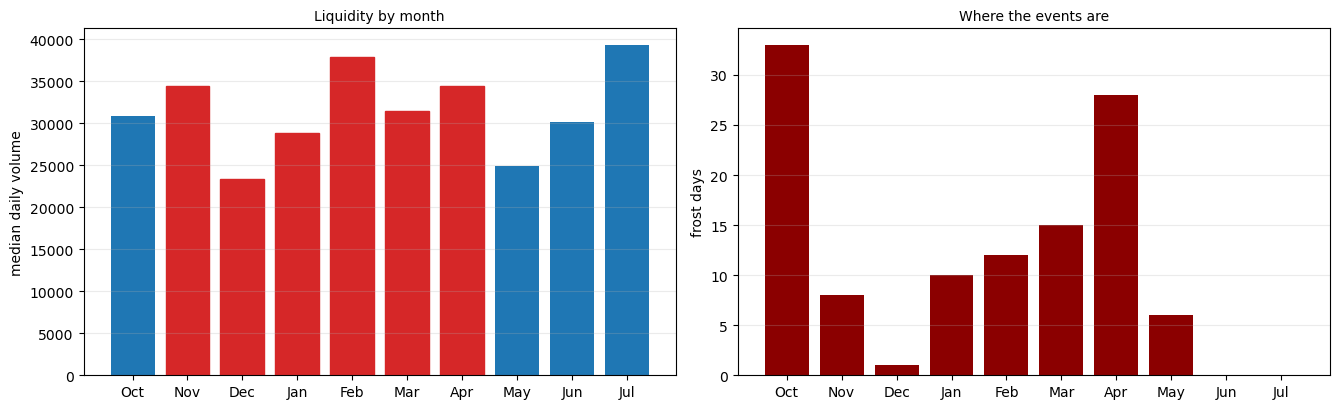

In [4]:
# --- Liquidity by month: is the contract trading when frost hits? -----------------
d2e = df.copy()
d2e["mm"] = d2e.index.month
liq = d2e.groupby("mm").agg(med_vol=("volume","median"), med_oi=("oi","median"),
                            n=("px","size"), frost=("shock","sum"))
liq = liq.reindex([10,11,12,1,2,3,4,5,6,7])
print("by calendar month (window is Oct -> Jul):")
print(liq.round(0).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.2))
o = [10,11,12,1,2,3,4,5,6,7]; lab = ["Oct","Nov","Dec","Jan","Feb","Mar","Apr","May","Jun","Jul"]
ax[0].bar(range(10), liq.med_vol.values, color="tab:blue")
ax[0].set_xticks(range(10)); ax[0].set_xticklabels(lab)
ax[0].set_ylabel("median daily volume"); ax[0].set_title("Liquidity by month", fontsize=10)
for i, m in enumerate(o):
    if m in FROST_MONTHS: ax[0].patches[i].set_color("tab:red")
ax[0].grid(alpha=.25, axis="y")
ax[1].bar(range(10), liq.frost.values, color="darkred")
ax[1].set_xticks(range(10)); ax[1].set_xticklabels(lab)
ax[1].set_ylabel("frost days"); ax[1].set_title("Where the events are", fontsize=10)
ax[1].grid(alpha=.25, axis="y")
fig.tight_layout(); plt.show()

## 2. Paper results

The local projection regresses the cumulative MATIF return, from the settlement before a frost-kill day to h trading days after it, on the binary shock. Five lagged daily returns enter as controls and standard errors are Newey-West (paper equation 8). Horizons before the event act as a placebo. The first figure is paper Figure 4. The event study after it takes the peak-kill day of each crop year as one event (paper Figure 5).

In [5]:
# --- Local projection estimator (paper equation 8) and a reporting helper ---------
def run_panel_lp(d, shock="shock", h_fwd=H_FWD, h_pre=H_PRE, lags=LAGS,
                 window=True, month_fe=False, alpha=ALPHA, cluster=False):
    d = d.sort_values(["symbol"]).sort_index()
    gp = d.groupby("symbol", sort=False)["logp"]
    base = gp.shift(1)
    ctrl = pd.concat({f"rl{k}": d.groupby("symbol", sort=False)["ret"].shift(k)
                      for k in range(1, lags+1)}, axis=1)
    z_pt  = stats.norm.ppf(1-alpha/2)
    z_sim = stats.norm.ppf(1-alpha/(2*h_fwd))
    rows = []
    for h in range(-h_pre, h_fwd+1):
        y = (gp.shift(-h) - base) * 100.0
        X = pd.concat([y.rename("y"), d[shock].rename("s"), ctrl,
                       d["symbol"].rename("g")], axis=1).dropna()
        if window: X = X[X.index.month.isin(FROST_MONTHS)]
        regs = ["s"] + list(ctrl.columns)
        if month_fe:
            fe = pd.get_dummies(X.index.month, prefix="m", drop_first=True).astype(float)
            fe.index = X.index
            X = pd.concat([X, fe], axis=1)
            regs += list(fe.columns)
        if len(X) < 50 or X.s.std() == 0: continue
        mod = sm.OLS(X.y, sm.add_constant(X[regs]))
        res = (mod.fit(cov_type="cluster", cov_kwds={"groups": X.g}) if cluster
               else mod.fit(cov_type="HAC", cov_kwds={"maxlags": abs(h)+5}))
        b, se = res.params["s"], res.bse["s"]
        rows.append(dict(h=h, beta=b, se=se, lo=b-z_pt*se, hi=b+z_pt*se,
                         lo_s=b-z_sim*se, hi_s=b+z_sim*se,
                         degenerate=(h < 0 and abs(h) <= lags+1), n=len(X)))
    return pd.DataFrame(rows).set_index("h")

def report(t, name, main_h=20):
    fwd = t[t.index > 0]; pre = t[(t.index < 0) & (~t.degenerate)]
    z = t.beta/t.se.replace(0, np.nan)
    pv = pd.Series(2*(1-stats.norm.cdf(z.abs())), index=t.index)
    peak = t.beta.abs().idxmax()
    mde = (stats.norm.ppf(1-ALPHA/2)+stats.norm.ppf(.80))*float(fwd.se.median())
    sim = bool(((fwd.lo_s > 0) | (fwd.hi_s < 0)).any())
    print(f"[{name}] n={int(t.n.median())}")
    print(f"  peak         {t.beta[peak]:+.2f}% at h={peak} (p={pv[peak]:.2f})")
    print(f"  h={main_h}         {t.beta[main_h]:+.2f}% [{t.lo[main_h]:+.2f},{t.hi[main_h]:+.2f}]")
    print(f"  pointwise    min p = {pv[fwd.index].min():.3f}")
    print(f"  SIMULTANEOUS {'significant' if sim else 'NOT significant'}")
    print(f"  MDE          +/-{mde:.2f}%")
    print(f"  placebo max  {pre.beta.abs().max():.2f}%")
    return dict(name=name, peak=t.beta[peak], b20=t.beta[main_h], mde=mde,
                sim=sim, minp=pv[fwd.index].min(), placebo=pre.beta.abs().max())

[all months, lag controls only] n=4142
  peak         +0.72% at h=18 (p=0.26)
  h=20         +0.53% [-0.80,+1.85]
  pointwise    min p = 0.241
  SIMULTANEOUS NOT significant
  MDE          +/-1.70%
  placebo max  0.50%


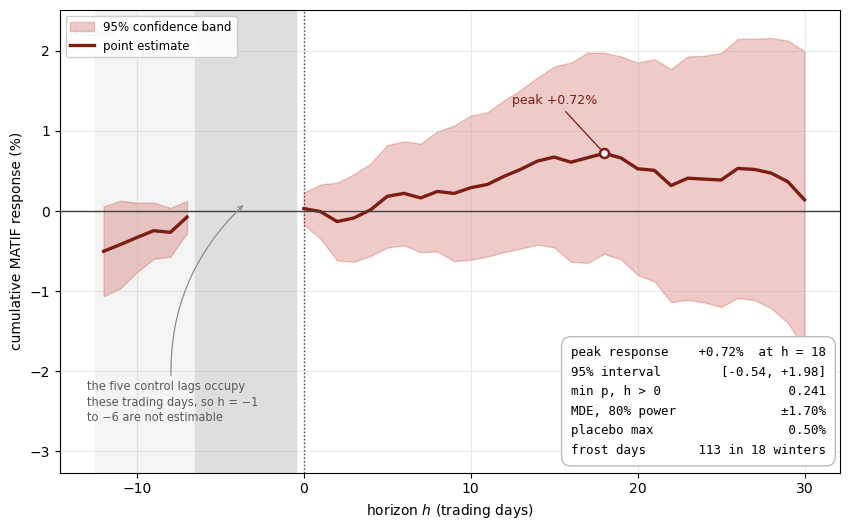

saved output/figures/fig4_local_projection.pdf and output/tables/lp_irf_newcrop_rostov.csv


In [6]:
# --- Paper Figure 4: local projection over 30 trading days ------------------------
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": .25})

irf_nc = run_panel_lp(df, window=False, month_fe=False)
r_nc   = report(irf_nc, "all months, lag controls only")

n_fire = int((df.shock > 0).sum())
n_wint = int(df.loc[df.shock > 0, "frost_season"].nunique())

def stats_box(t):
    fwd = t[t.index > 0]; pre = t[(t.index < 0) & (~t.degenerate)]
    z   = t.beta / t.se.replace(0, np.nan)
    pv  = pd.Series(2*(1-stats.norm.cdf(z.abs())), index=t.index)
    h   = int(t.beta.abs().idxmax())
    mde = (stats.norm.ppf(1-ALPHA/2)+stats.norm.ppf(.80))*float(fwd.se.median())
    L = [("peak response",  f"{t.beta[h]:+.2f}%  at h = {h}"),
         ("95% interval",   f"[{t.lo[h]:+.2f}, {t.hi[h]:+.2f}]"),
         ("min p, h > 0",   f"{pv[fwd.index].min():.3f}"),
         ("MDE, 80% power", f"±{mde:.2f}%"),
         ("placebo max",    f"{pre.beta.abs().max():.2f}%"),
         ("frost days",     f"{n_fire} in {n_wint} winters")]
    w = max(len(a) for a, _ in L)                 # pad BOTH columns so every
    v = max(len(b) for _, b in L)                 # line is the same length
    return "\n".join(f"{a:<{w}}   {b:>{v}}" for a, b in L), mde, h

fig, ax = plt.subplots(figsize=(8.6, 5.4))
t    = irf_nc
post = t[t.index >= 0]
pre  = t[(t.index < 0) & (~t.degenerate)]

ax.axvspan(pre.index.min()-.5, -0.5, color="0.955", zorder=0)
ax.axvspan(-(LAGS+1)-.5, -0.5, color="0.87", zorder=0)      # the lag-control days

for seg in (pre, post):
    ax.fill_between(seg.index, seg.lo, seg.hi, color="#c0392b", alpha=.26)
    ax.plot(seg.index, seg.beta, color="#7b1d13", lw=2.4)
ax.fill_between([], [], [], color="#c0392b", alpha=.26, label="95% confidence band")
ax.plot([], [], color="#7b1d13", lw=2.4, label="point estimate")
ax.axhline(0, color="0.25", lw=1.0)
ax.axvline(0, color="0.25", lw=1.0, ls=":")

box, mde_nc, h_pk = stats_box(t)
ax.plot(h_pk, t.beta[h_pk], "o", ms=6.5, mfc="white", mec="#7b1d13", mew=1.8, zorder=6)
ax.annotate(f"peak {t.beta[h_pk]:+.2f}%", xy=(h_pk, t.beta[h_pk]),
            xytext=(h_pk-5.5, t.beta[h_pk]+0.62), fontsize=9, color="#7b1d13",
            arrowprops=dict(arrowstyle="-", color="#7b1d13", lw=.9))

ax.set_ylim(float(t.lo.min())-1.55, float(t.hi.max())+0.35)

ax.text(.012, .965, "placebo", transform=ax.transAxes,
        fontsize=8.5, color="0.4", va="top", ha="left")
ax.annotate("the five control lags occupy\nthese trading days, so h = −1\nto −6 are not estimable",
            xy=(-(LAGS+1)/2 - 0.5, 0.10), xycoords="data",
            xytext=(.035, .105), textcoords="axes fraction",
            fontsize=8.2, color="0.35", ha="left", va="bottom", linespacing=1.4,
            arrowprops=dict(arrowstyle="->", color="0.55", lw=.9,
                            connectionstyle="arc3,rad=-0.25"))

ax.text(.982, .035, box, transform=ax.transAxes, ha="right", va="bottom",
        fontsize=9.0, family="monospace", linespacing=1.65,
        bbox=dict(fc="white", ec="0.72", alpha=.95, boxstyle="round,pad=0.75"))

ax.set_xlabel("horizon $h$ (trading days)")
ax.set_ylabel("cumulative MATIF response (%)")
ax.legend(fontsize=8.5, loc="upper left", framealpha=.93)
fig.tight_layout()
for e in ("pdf","png"): fig.savefig(FIGDIR/f"fig4_local_projection.{e}", dpi=200, bbox_inches="tight")
plt.show()
irf_nc.to_csv(OUT / "lp_irf_newcrop_rostov.csv")
print("saved output/figures/fig4_local_projection.pdf and output/tables/lp_irf_newcrop_rostov.csv")

In [7]:
# --- Raw difference in 18-day returns, frost vs non-frost days (paper section 2.4) ---
H  = 18
gp = df.groupby("symbol", sort=False)["logp"]
y  = ((gp.shift(-H) - gp.shift(1)) * 100).rename("y18")
d  = pd.concat([y, df.shock.rename("D")], axis=1).dropna()

a, b = d.loc[d.D == 1, "y18"], d.loc[d.D == 0, "y18"]
print(f"frost days      n={len(a):>5}   mean 18-day return  {a.mean():+.2f}%")
print(f"non-frost days  n={len(b):>5}   mean 18-day return  {b.mean():+.2f}%")
print(f"raw difference                                 {a.mean()-b.mean():+.2f}%")
print(f"regression beta(20)                            {irf_nc.beta[20]:+.2f}%")

frost days      n=  113   mean 18-day return  +1.06%
non-frost days  n= 3945   mean 18-day return  +0.27%
raw difference                                 +0.80%
regression beta(20)                            +0.53%


Cross-sectional tests (H0: CAR = 0):
 h     kind  n    mean  median   p_t  p_wilcoxon   pos  p_sign
20      raw 16   1.306   1.178 0.353       0.156 10/16   0.454
20 mean-adj 16  -3.171  -1.964 0.229       0.298  7/16   0.804
30      raw 16   1.962   0.389 0.303       0.323 10/16   0.454
30 mean-adj 16  -4.752  -1.398 0.208       0.298  6/16   0.454
60      raw 16   2.899   2.092 0.261       0.348  9/16   0.804
60 mean-adj 16 -10.530  -4.852 0.178       0.464  7/16   0.804

dose-response h=20: Spearman rho = -0.08 (p = 0.78)
severity 0.003 to 0.244; largest is 1.1x the next


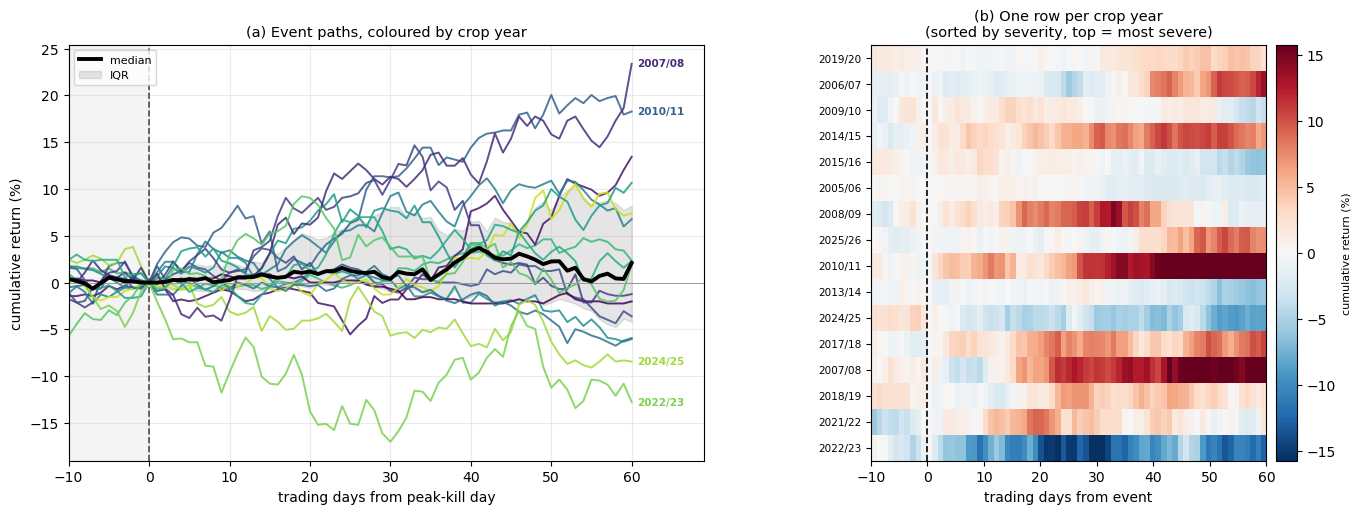

In [8]:
# --- Paper Figure 5: event study, one event per crop year (peak-kill day) ---------
PRE, POST  = 10, 60          # trading days shown before and after the event
EST0, EST1 = -60, -11        # estimation window for the mean-adjusted benchmark
CAR_H      = [20, 30, 60]    # cumulative-return horizons for the tests

kd = df[df.shock > 0]
ev = kd.loc[kd.groupby("frost_season")["kill_incr"].idxmax()].sort_index()

paths, rows = {}, []
for d0, r in ev.iterrows():
    c = df[df.symbol == r.symbol]; i = c.index.get_loc(d0)
    if i - PRE < 0 or i + 1 >= len(c): continue
    ret = c["ret"].values
    mu = np.nanmean(ret[max(0, i+EST0): i+EST1])
    sd = np.nanstd(ret[max(0, i+EST0): i+EST1])
    hi = min(i + POST, len(c) - 1)
    rel  = np.arange(i-PRE, hi+1) - i
    post = np.concatenate([[0.0], np.nancumsum(ret[i+1:hi+1])]) * 100
    pre_ = -np.nancumsum(ret[i:i-PRE:-1])[::-1] * 100
    paths[r.frost_season] = pd.Series(np.concatenate([pre_, post]), index=rel)
    row = dict(season=r.frost_season, symbol=r.symbol, date=d0.date(),
               severity=r.kill_incr, month=d0.month, pre_sd=float(sd*100))
    for h in CAR_H:
        if i + h < len(c):
            row[f"CAR{h}"] = float(np.nansum(ret[i+1:i+h+1]) * 100)
            row[f"AAR{h}"] = float((np.nansum(ret[i+1:i+h+1]) - h*mu) * 100)
    rows.append(row)

E = pd.DataFrame(rows).set_index("season")
P = pd.DataFrame(paths)
P = P[[s for s in E.severity.sort_values(ascending=False).index if s in P.columns]]

fig = plt.figure(figsize=(16.5, 5.4))
gs  = fig.add_gridspec(1, 2, width_ratios=[2, 1.5], wspace=.30)

# (a) paths coloured by crop year, extremes labelled
ax = fig.add_subplot(gs[0])
yrs = sorted(P.columns, key=lambda s: int(s[:4]))
col = dict(zip(yrs, plt.cm.viridis(np.linspace(0, .92, len(yrs)))))
for s in P.columns:
    ax.plot(P.index, P[s], color=col[s], lw=1.4, alpha=.85)
ax.plot(P.index, P.median(axis=1), color="k", lw=2.8, label="median", zorder=6)
ax.fill_between(P.index, P.quantile(.25, axis=1), P.quantile(.75, axis=1),
                color="k", alpha=.10, label="IQR", zorder=1)
end = P.iloc[-1].dropna().sort_values()
for s in list(end.index[:2]) + list(end.index[-2:]):
    ax.annotate(s, (P.index[-1], end[s]), fontsize=7.5, color=col[s], weight="bold",
                xytext=(4, 0), textcoords="offset points", va="center")
ax.axvline(0, color="0.3", lw=1.2, ls="--"); ax.axhline(0, color="0.6", lw=.7)
ax.axvspan(-PRE, 0, color="0.955"); ax.set_xlim(-PRE, POST + 9)
ax.set_xlabel("trading days from peak-kill day"); ax.set_ylabel("cumulative return (%)")
ax.set_title("(a) Event paths, coloured by crop year", fontsize=10.5)
ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=.25)

# (b) heatmap: one row per crop year, fully identifiable
ax = fig.add_subplot(gs[1]); M = P.T
v = np.nanpercentile(np.abs(M.values), 97)
im = ax.imshow(M.values, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v,
               extent=[P.index[0], P.index[-1], len(M), 0], interpolation="nearest")
ax.set_yticks(np.arange(len(M)) + .5); ax.set_yticklabels(M.index, fontsize=7.5)
ax.axvline(0, color="k", lw=1.2, ls="--"); ax.grid(False)
ax.set_xlabel("trading days from event")
ax.set_title("(b) One row per crop year\n(sorted by severity, top = most severe)", fontsize=10.5)
cb = fig.colorbar(im, ax=ax, pad=.02); cb.set_label("cumulative return (%)", fontsize=8)

tests = []
for h in CAR_H:
    for tag, cn in (("raw", f"CAR{h}"), ("mean-adj", f"AAR{h}")):
        if cn not in E: continue
        x = E[cn].dropna()
        if len(x) < 6: continue
        npos = int((x > 0).sum())
        tests.append(dict(h=h, kind=tag, n=len(x), mean=x.mean(), median=x.median(),
                          p_t=stats.ttest_1samp(x, 0).pvalue,
                          p_wilcoxon=stats.wilcoxon(x).pvalue, pos=f"{npos}/{len(x)}",
                          p_sign=stats.binomtest(npos, len(x), .5).pvalue))
T = pd.DataFrame(tests)
print("Cross-sectional tests (H0: CAR = 0):")
print(T.round(3).to_string(index=False))
m = E[["severity","CAR20"]].dropna(); rho, prho = stats.spearmanr(m.severity, m.CAR20)
print(f"\ndose-response h=20: Spearman rho = {rho:+.2f} (p = {prho:.2f})")
print(f"severity {E.severity.min():.3f} to {E.severity.max():.3f}; largest is "
      f"{E.severity.max()/E.severity.nlargest(2).iloc[-1]:.1f}x the next")
E.to_csv(OUT/"event_study_per_event.csv"); T.to_csv(OUT/"event_study_tests.csv", index=False)
for e in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig5_event_study.{e}", dpi=200, bbox_inches="tight")
plt.show()

## 3. Robustness checks (not in the paper)

- Alternative specifications, a November-to-April window, month fixed effects and contract-clustered errors
- Old-crop nearby versus new-crop contracts
- How the controls and seasonality move the estimate, and how much kill falls on non-trading days
- Long horizons up to 60 trading days
- Event-study details and the spring subsample
- Volatility response
- Rank-graded shock and a severity ladder

In [9]:
# --- Alternative specifications ---------------------------------------------------
irf_win = run_panel_lp(df)                                   # Nov-Apr window, five lags
irf_fe  = run_panel_lp(df, window=False, month_fe=True)      # all months, lags + month FE
report(irf_win, "Nov-Apr window")
report(irf_fe,  "all months + month FE")

print("\ncluster-robust by contract, Nov-Apr window (21 clusters, indicative):")
irf_cl = run_panel_lp(df, cluster=True)
print(f"  h=20 {irf_cl.beta[20]:+.2f}%  [{irf_cl.lo[20]:+.2f},{irf_cl.hi[20]:+.2f}]")

[Nov-Apr window] n=2627
  peak         -0.99% at h=30 (p=0.37)
  h=20         -0.06% [-1.78,+1.65]
  pointwise    min p = 0.290
  SIMULTANEOUS NOT significant
  MDE          +/-2.24%
  placebo max  0.45%
[all months + month FE] n=4142
  peak         +0.64% at h=18 (p=0.31)
  h=20         +0.42% [-0.89,+1.73]
  pointwise    min p = 0.278
  SIMULTANEOUS NOT significant
  MDE          +/-1.68%
  placebo max  0.57%

cluster-robust by contract, Nov-Apr window (21 clusters, indicative):
  h=20 -0.06%  [-1.59,+1.46]


[old-crop nearby, Nov-Apr] n=2627
  peak         +1.01% at h=27 (p=0.38)
  h=20         +0.75% [-1.29,+2.79]
  pointwise    min p = 0.332
  SIMULTANEOUS NOT significant
  MDE          +/-2.48%
  placebo max  0.85%


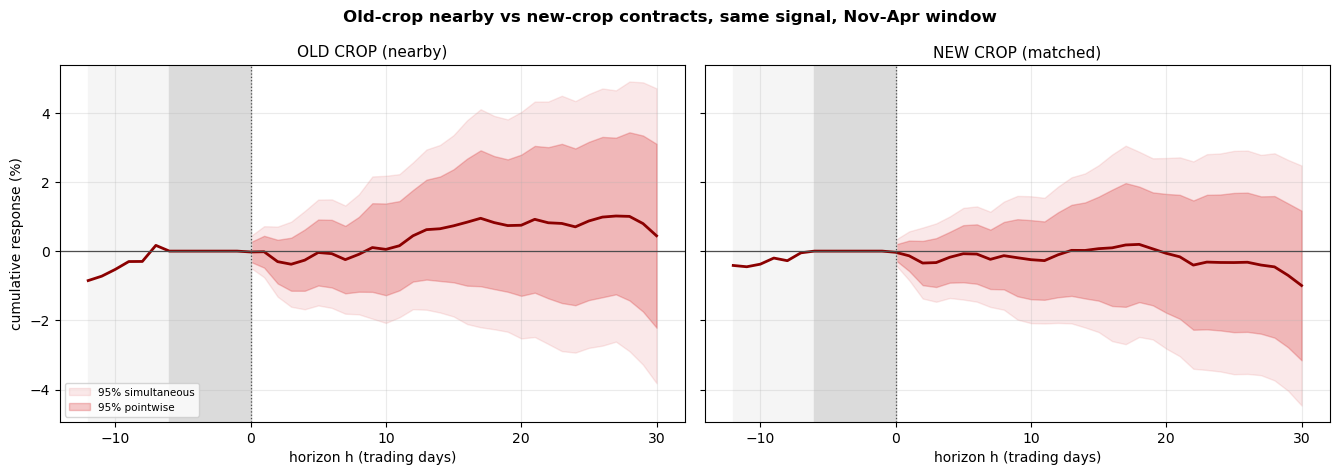

In [10]:
# --- Old crop vs new crop: does matching the crop year matter? --------------------
irf_oc = None
if NEARBY:
    nb = pd.read_csv(NEARBY[-1])
    tcol = next(c for c in ["Time","Date","date"] if c in nb.columns)
    pcol = next(c for c in ["Latest","Last","Close","Settle"] if c in nb.columns)
    nb = pd.DataFrame({"date": pd.to_datetime(nb[tcol], errors="coerce"),
                       "px": pd.to_numeric(nb[pcol], errors="coerce")}).dropna()
    nb = nb.set_index("date").sort_index()
    nb = nb[~nb.index.duplicated(keep="last")]
    nb["symbol"] = "NEARBY"; nb["logp"] = np.log(nb.px); nb["ret"] = nb.logp.diff()
    nb = nb.join(sig.set_index("date")[["kill_incr"]])
    nb["kill_incr"] = nb.kill_incr.fillna(0.0)
    nb["shock"] = (nb.kill_incr > 0).astype(float)
    nb = nb.loc[df.index.min():df.index.max()]     # same sample period as the panel
    irf_oc = run_panel_lp(nb)
    r_oc = report(irf_oc, "old-crop nearby, Nov-Apr")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
for a, (t, ttl) in zip(ax, [(irf_oc, "OLD CROP (nearby)"), (irf_win, "NEW CROP (matched)")]):
    if t is None: a.axis("off"); continue
    a.fill_between(t.index, t.lo_s, t.hi_s, color="tab:red", alpha=.10, label="95% simultaneous")
    a.fill_between(t.index, t.lo, t.hi, color="tab:red", alpha=.25, label="95% pointwise")
    a.plot(t.index, t.beta, color="darkred", lw=2)
    a.axhline(0, color="0.3", lw=.9); a.axvline(0, color="0.3", lw=.9, ls=":")
    a.axvspan(t.index.min(), 0, color="0.96")
    deg = t[t.degenerate]
    if len(deg): a.axvspan(deg.index.min(), 0, color="0.86")
    a.set_xlabel("horizon h (trading days)"); a.set_title(ttl, fontsize=11); a.grid(alpha=.25)
ax[0].set_ylabel("cumulative response (%)"); ax[0].legend(fontsize=7.5, loc="lower left")
fig.suptitle("Old-crop nearby vs new-crop contracts, same signal, Nov-Apr window",
             fontsize=12, weight="bold")
fig.tight_layout()
for e in ("pdf", "png"):
    fig.savefig(FIGDIR / f"robustness_old_vs_new_crop.{e}", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
# --- How the controls move beta at h = 18 -----------------------------------------
H = 18
gp   = df.groupby("symbol", sort=False)["logp"]
y    = ((gp.shift(-H) - gp.shift(1)) * 100).rename("y")
ctrl = pd.concat({f"rl{k}": df.groupby("symbol", sort=False)["ret"].shift(k)
                  for k in range(1, LAGS+1)}, axis=1)
X  = pd.concat([y, df.shock.rename("s"), ctrl], axis=1).dropna()
fe = pd.get_dummies(X.index.month, prefix="m", drop_first=True).astype(float)
fe.index = X.index
X  = pd.concat([X, fe], axis=1)

def beta(regs, label):
    m = sm.OLS(X.y, sm.add_constant(X[regs])).fit(cov_type="HAC",
                                                  cov_kwds={"maxlags": H+5})
    print(f"{label:<26} beta = {m.params['s']:+.2f}%")

print(f"matched sample n = {len(X):,}   frost days = {int(X.s.sum())}\n")
beta(["s"],                                        "no controls")
beta(["s"] + list(ctrl.columns),                   "lags only (paper eq. 8)")
beta(["s"] + list(fe.columns),                     "month dummies only")
beta(["s"] + list(ctrl.columns) + list(fe.columns), "lags + month dummies")

matched sample n = 3,953   frost days = 113

no controls                beta = +0.81%
lags only (paper eq. 8)    beta = +0.72%
month dummies only         beta = +0.72%
lags + month dummies       beta = +0.64%


In [12]:
# --- Seasonal composition: frost share and mean 20-day return by month ------------
H  = 20
gp = df.groupby("symbol", sort=False)["logp"]
y  = ((gp.shift(-H) - gp.shift(1)) * 100).rename("y")
m  = pd.concat([y, df.shock.rename("D")], axis=1).dropna()
m["month"] = m.index.month

t = m.groupby("month").agg(days=("D","size"), frost=("D","sum"), mean_y=("y","mean"))
t["frost_share"] = t.frost / t.frost.sum()
t["day_share"]   = t.days  / t.days.sum()
print(t.round(3).to_string())
print(f"\nseasonal contamination in the raw difference: "
      f"{float(((t.frost_share - t.day_share) * t.mean_y).sum()):+.2f}%")

       days  frost  mean_y  frost_share  day_share
month                                             
1       451   10.0  -0.340        0.088      0.112
2       424   12.0  -0.256        0.106      0.106
3       457   15.0   0.542        0.133      0.114
4       415   28.0   1.881        0.248      0.103
5       449    6.0  -0.513        0.053      0.112
6       450    0.0   0.838        0.000      0.112
7        46    0.0   1.886        0.000      0.011
10      444   33.0   0.140        0.292      0.111
11      450    8.0  -0.375        0.071      0.112
12      430    1.0   0.696        0.009      0.107

seasonal contamination in the raw difference: +0.18%


In [13]:
# --- Mean 20-day return by month, frost vs non-frost days -------------------------
H = 20
gp = df.groupby("symbol", sort=False)["logp"]
y  = ((gp.shift(-H) - gp.shift(1)) * 100).rename("y")
m  = pd.concat([y, df.shock.rename("D")], axis=1).dropna()
m["month"] = m.index.month

print(m[m.month.isin([10,11,1,2,3,4])]
        .groupby(["month","D"])["y"].agg(["size","mean"]).unstack("D").round(2).to_string())

f   = (m.D == 1).astype(float)
fwd = f.iloc[::-1].rolling(H, min_periods=1).sum().iloc[::-1] - f
c0  = (m.D == 0)
print(f"\nD=0 days with a frost day inside their {H}-day window: "
      f"{int((fwd[c0] > 0).sum()):,} of {int(c0.sum()):,} ({(fwd[c0] > 0).mean():.0%})")

      size      mean      
D      0.0 1.0   0.0   1.0
month                     
1      441  10 -0.42  3.19
2      412  12 -0.20 -2.03
3      442  15  0.55  0.19
4      387  28  1.98  0.50
10     411  33  0.03  1.51
11     442   8 -0.40  0.80

D=0 days with a frost day inside their 20-day window: 814 of 3,903 (21%)


In [14]:
# --- Kill that falls on weekends and holidays, before rolling ---------------------
sig_raw = pd.read_csv(SIGNAL, parse_dates=["date"])
tdays   = pd.DatetimeIndex(sorted(pan.date.unique()))
cal     = sig_raw[(sig_raw.kill_incr > 0) & sig_raw.date.dt.month.isin(FROST_MONTHS)]
lost    = cal[~cal.date.isin(tdays)]
print(f"calendar days firing, Nov-Apr      {len(cal)}")
print(f"  on a trading day                 {len(cal)-len(lost)}")
print(f"  on a weekend or holiday          {len(lost)}  ({len(lost)/len(cal):.0%})")
print(f"  share of kill mass lost          {lost.kill_incr.sum()/cal.kill_incr.sum():.0%}")
print(lost.date.dt.day_name().value_counts().to_string())

calendar days firing, Nov-Apr      103
  on a trading day                 60
  on a weekend or holiday          43  (42%)
  share of kill mass lost          48%
date
Sunday      18
Saturday    15
Friday       5
Monday       3
Tuesday      1
Thursday     1


In [15]:
# --- Per-trade view: one trade per cold snap, 18-day holding period ---------------
H, GAP = 18, 10
gp = df.groupby("symbol", sort=False)["logp"]
y  = ((gp.shift(-H) - gp.shift(1)) * 100)

fire = df.index[df.shock > 0]
eid  = (pd.Series(fire).diff().dt.days.fillna(999) > GAP).cumsum().values
Ev   = (pd.DataFrame({"eid": eid, "y": y.loc[fire].values})
          .dropna().groupby("eid")["y"].mean())

bench = y.loc[df.index[df.shock == 0]].dropna().mean()
x     = Ev - bench
yrs   = int(df.frost_season.nunique())

s = x.mean() / x.std()
se = np.sqrt((1 + 0.5*s**2) / len(x))
print(f"events {len(x)} over {yrs} crop years = {len(x)/yrs:.1f}/yr")
print(f"excess mean {x.mean():+.2f}%   sd {x.std():.2f}%")
print(f"per-trade Sharpe {s:.3f}  [{s-1.96*se:+.3f}, {s+1.96*se:+.3f}]")
print(f"annualised {s*np.sqrt(len(x)/yrs):+.2f}")

events 44 over 21 crop years = 2.1/yr
excess mean +0.63%   sd 4.77%
per-trade Sharpe 0.131  [-0.165, +0.428]
annualised +0.19


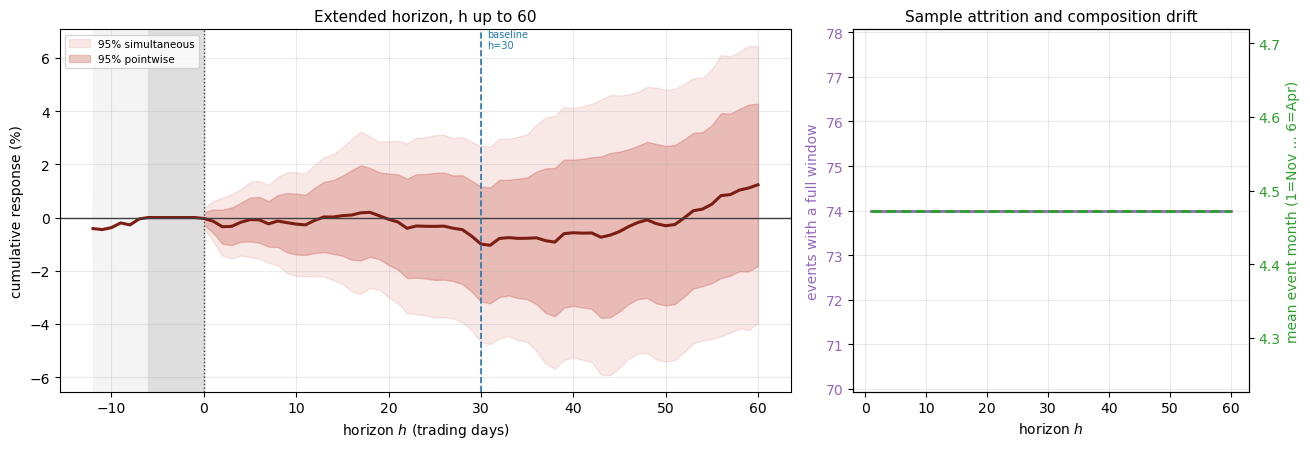

events at h=1: 74  |  at h=60: 74  (100% retained)
mean event month drifts 4.47 -> 4.47
[new-crop, h<=60] n=2627
  peak         +1.23% at h=60 (p=0.43)
  h=40         -0.57% [-3.32,+2.17]
  pointwise    min p = 0.290
  SIMULTANEOUS NOT significant
  MDE          +/-3.10%
  placebo max  0.45%


In [16]:
# --- Long horizon up to 60 days, and how the event sample changes with h ----------
# Windows end on 31 July, so an April event plus 60 trading days still fits. The
# right panel shows whether the event sample changes as h grows.
H_LONG = 60
irf_long = run_panel_lp(df, h_fwd=H_LONG, h_pre=H_PRE)

# composition: which events still have a full forward window at each horizon?
gp_l = df.groupby("symbol", sort=False)["logp"]
comp = []
for h in range(1, H_LONG+1):
    y = gp_l.shift(-h)
    m = y.notna() & (df.shock > 0) & df.index.month.isin(FROST_MONTHS)
    sub = df[m]
    comp.append(dict(h=h, n_events=len(sub),
                     mean_month=(pd.Series(sub.index.month)
                                 .map({11:1,12:2,1:3,2:4,3:5,4:6}).mean()
                                 if len(sub) else np.nan)))
comp = pd.DataFrame(comp).set_index("h")

fig, ax = plt.subplots(1, 2, figsize=(13.2, 4.6),
                       gridspec_kw={"width_ratios":[1.85, 1]})
t = irf_long
ax[0].fill_between(t.index, t.lo_s, t.hi_s, color="#c0392b", alpha=.11, label="95% simultaneous")
ax[0].fill_between(t.index, t.lo, t.hi, color="#c0392b", alpha=.26, label="95% pointwise")
ax[0].plot(t.index, t.beta, color="#7b1d13", lw=2.2)
ax[0].axhline(0, color="0.25", lw=1); ax[0].axvline(0, color="0.25", lw=1, ls=":")
ax[0].axvline(30, color="tab:blue", lw=1.2, ls="--")
ax[0].text(30.7, ax[0].get_ylim()[1]*.9, "baseline\nh=30", fontsize=7, color="tab:blue")
degl = t[t.degenerate]
ax[0].axvspan(t.index.min(), 0, color="0.955")
if len(degl): ax[0].axvspan(degl.index.min(), 0, color="0.87")
ax[0].set_xlabel("horizon $h$ (trading days)")
ax[0].set_ylabel("cumulative response (%)")
ax[0].set_title(f"Extended horizon, h up to {H_LONG}", fontsize=11)
ax[0].legend(fontsize=7.5, loc="upper left")

a2 = ax[1]; a2.plot(comp.index, comp.n_events, color="tab:purple", lw=2)
a2.set_xlabel("horizon $h$"); a2.set_ylabel("events with a full window", color="tab:purple")
a2.tick_params(axis="y", labelcolor="tab:purple")
a3 = a2.twinx(); a3.plot(comp.index, comp.mean_month, color="tab:green", lw=2, ls="--")
a3.set_ylabel("mean event month (1=Nov ... 6=Apr)", color="tab:green")
a3.tick_params(axis="y", labelcolor="tab:green"); a3.grid(False)
a2.set_title("Sample attrition and composition drift", fontsize=11)
fig.tight_layout()
for e in ("pdf","png"): fig.savefig(FIGDIR/f"robustness_long_horizon.{e}", dpi=200, bbox_inches="tight")
plt.show()

print(f"events at h=1: {comp.n_events.iloc[0]}  |  at h={H_LONG}: {comp.n_events.iloc[-1]}"
      f"  ({comp.n_events.iloc[-1]/max(comp.n_events.iloc[0],1):.0%} retained)")
print(f"mean event month drifts {comp.mean_month.iloc[0]:.2f} -> {comp.mean_month.iloc[-1]:.2f}")
_ = report(irf_long, f"new-crop, h<={H_LONG}", main_h=min(40, H_LONG))

In [17]:
# --- Attrition check: do all events keep a full 60-day forward window? ------------
# The last frost month is April and windows end on 31 July, about 66 trading days later.
gp = df.groupby("symbol", sort=False)["logp"]
m  = (df.shock > 0) & df.index.month.isin(FROST_MONTHS)
for h in (30, 60):
    print(f"h={h}: {int((m & gp.shift(-h).notna()).sum())} of {int(m.sum())} "
          f"events keep a full forward window")

h=30: 74 of 74 events keep a full forward window
h=60: 74 of 74 events keep a full forward window


In [18]:
# --- Summary table ----------------------------------------------------------------
def summarise(t, name, main_h=20):
    fwd = t[t.index > 0]
    z = t.beta/t.se.replace(0, np.nan)
    pv = pd.Series(2*(1-stats.norm.cdf(z.abs())), index=t.index)
    pre = t[(t.index < 0) & (~t.degenerate)] if "degenerate" in t else None
    return dict(specification=name, n=int(t.n.median()),
                beta_h20=t.beta.get(main_h, np.nan),
                ci_lo=t.lo.get(main_h, np.nan), ci_hi=t.hi.get(main_h, np.nan),
                peak=t.beta[t.beta.abs().idxmax()], peak_h=t.beta.abs().idxmax(),
                min_p=pv[fwd.index].min(),
                sim_sig=bool(((fwd.lo_s>0)|(fwd.hi_s<0)).any()),
                mde=(stats.norm.ppf(1-ALPHA/2)+stats.norm.ppf(.80))*float(fwd.se.median()),
                placebo=(pre.beta.abs().max() if pre is not None and len(pre) else np.nan))

S = [summarise(irf_nc,   "New crop, all months (paper)"),
     summarise(irf_win,  "New crop, Nov-Apr"),
     summarise(irf_cl,   "New crop, Nov-Apr, clustered by contract"),
     summarise(irf_long, f"New crop, Nov-Apr, h<={H_LONG}", main_h=20)]
if irf_oc is not None: S.append(summarise(irf_oc, "Old crop nearby, Nov-Apr"))
S = pd.DataFrame(S)
print(S.round(3).to_string(index=False))
S.to_csv(OUT/"lp_summary_table.csv", index=False)

# LaTeX fragment for Overleaf
tex = S.copy()
tex["beta_h20"] = tex.apply(lambda r: f"{r.beta_h20:+.2f} [{r.ci_lo:+.2f}, {r.ci_hi:+.2f}]", axis=1)
tex["MDE"] = tex.mde.map(lambda v: f"$\\pm${v:.2f}")
tex = tex[["specification","n","beta_h20","peak","min_p","MDE","placebo"]]
tex.columns = ["Specification","$n$","$\\beta(20)$ [95\\% CI]","Peak","Min $p$","MDE","Placebo"]
(OUT/"lp_summary_table.tex").write_text(
    tex.to_latex(index=False, escape=False, float_format="%.2f",
                 caption="Local projection of MATIF new-crop returns on the Rostov "
                         "frost-kill shock. Percentage points.",
                 label="tab:lp"))
print("\nwritten:", (OUT / "lp_summary_table.tex").relative_to(ROOT))

                           specification    n  beta_h20  ci_lo  ci_hi   peak  peak_h  min_p  sim_sig   mde  placebo
            New crop, all months (paper) 4142     0.528 -0.799  1.855  0.721      18  0.241    False 1.697    0.503
                       New crop, Nov-Apr 2627    -0.065 -1.781  1.652 -0.995      30  0.290    False 2.240    0.453
New crop, Nov-Apr, clustered by contract 2627    -0.065 -1.586  1.457 -0.995      30  0.343    False 1.870    0.453
                New crop, Nov-Apr, h<=60 2627    -0.065 -1.781  1.652  1.233      60  0.290    False 3.100    0.453
                Old crop nearby, Nov-Apr 2627     0.747 -1.292  2.786  1.014      27  0.332    False 2.479    0.852

written: output/tables/lp_summary_table.tex


In [19]:
# --- Event-study details: kill per crop year and what CAR20 moves with ------------
kd   = df[df.shock > 0]
peak = kd.loc[kd.groupby("frost_season")["kill_incr"].idxmax()]
tot  = kd.groupby("frost_season")["kill_incr"].agg(total="sum", ndays="size", peakday="max")
tot["peak_month"] = pd.Series(peak.index.month.values, index=peak.frost_season.values)
print(tot.sort_values("peakday", ascending=False).round(4).to_string())

print("\ndropped from the event study:", sorted(set(kd.frost_season.dropna()) - set(E.index)))
for _, r in peak.iterrows():
    if r.frost_season in E.index: continue
    c = df[df.symbol == r.symbol]
    print(f"  {r.frost_season}: peak at position {c.index.get_loc(_)} of {len(c)}")

m = E.join(tot[["total", "ndays"]])
m["yr"] = [int(s[:4]) for s in m.index]
for col in ("severity", "total", "ndays", "yr"):
    rho, p = stats.spearmanr(m[col], m.CAR20)
    print(f"Spearman CAR20 vs {col:<9} rho = {rho:+.2f}   p = {p:.2f}")

               total  ndays  peakday  peak_month
frost_season                                    
2019/20       0.4423     10   0.2444          11
2006/07       0.3858      7   0.2234           2
2009/10       0.3165      4   0.1804          10
2014/15       0.3437      4   0.1717          10
2015/16       0.3245     13   0.1633          10
2005/06       0.2769      6   0.1199          10
2008/09       0.2132      7   0.0913           4
2025/26       0.1859     17   0.0779          12
2010/11       0.1432     13   0.0770          10
2013/14       0.1707      4   0.0749          10
2024/25       0.1661      7   0.0569           4
2023/24       0.1047      4   0.0525          10
2017/18       0.0865      4   0.0372           4
2007/08       0.0299      1   0.0299          11
2018/19       0.0308      2   0.0213           4
2016/17       0.0145      2   0.0092          10
2021/22       0.0265      5   0.0074          10
2022/23       0.0057      3   0.0027           4

dropped from the ev

In [20]:
# --- Event study split into autumn and late winter / spring -----------------------
m = E.copy()
m["mon"] = [d.month for d in pd.to_datetime(m.date)]
m["season_half"] = np.where(m.mon.isin([10, 11, 12]), "autumn", "late winter / spring")
print(m.groupby("season_half")[["severity", "CAR20"]]
        .agg(["size", "mean", "median"]).round(3).to_string())
for k, g in m.groupby("season_half"):
    if len(g) > 4:
        rho, p = stats.spearmanr(g.severity, g.CAR20)
        print(f"{k:<22} Spearman rho = {rho:+.2f}  p = {p:.2f}  (n={len(g)})")

                     severity               CAR20              
                         size   mean median  size   mean median
season_half                                                    
autumn                     10  0.115  0.099    10  2.368  1.392
late winter / spring        6  0.072  0.047     6 -0.465  0.105
autumn                 Spearman rho = -0.24  p = 0.51  (n=10)
late winter / spring   Spearman rho = +0.37  p = 0.47  (n=6)


In [21]:
# --- Spring subsample: largest spring kill day per crop year ----------------------
# Peak-day selection keeps one event per winter, which can hide spring frosts.
SPRING = [3, 4, 5]
kd = df[df.shock > 0]
sp = kd[kd.index.month.isin(SPRING)]

print(f"spring firing days      {len(sp)} across {sp.frost_season.nunique()} crop years")
print(f"peak-kill events in spring: "
      f"{int(pd.to_datetime(E.date).dt.month.isin(SPRING).sum())} of {len(E)}\n")

# largest spring increment per crop year, regardless of the annual peak
sev = kd.groupby("frost_season")["kill_incr"].max().rename("annual_peak")
spv = sp.loc[sp.groupby("frost_season")["kill_incr"].idxmax()]
cmp = spv.set_index("frost_season")[["kill_incr"]].rename(
        columns={"kill_incr": "spring_peak"}).join(sev)
cmp["spring_is_annual_peak"] = np.isclose(cmp.spring_peak, cmp.annual_peak)
print(cmp.sort_values("spring_peak", ascending=False).round(4).to_string())
print(f"\nhidden by peak-day selection: "
      f"{int((~cmp.spring_is_annual_peak).sum())} crop years\n")

# rerun the event study on the spring peak of each crop year
PRE_S = 9                                   # pre-event window in trading days
rows = []
for d0, r in spv.iterrows():
    c = df[df.symbol == r.symbol]; i = c.index.get_loc(d0)
    if i - PRE_S < 0 or i + 20 >= len(c):
        print(f"  skipped {r.frost_season} ({d0.date()}, position {i} of {len(c)})")
        continue
    ret = c["ret"].values
    row = dict(season=r.frost_season, date=d0.date(), month=d0.month,
               severity=r.kill_incr)
    for h in (20, 30):
        if i + h < len(c):
            row[f"CAR{h}"] = float(np.nansum(ret[i:i+h+1]) * 100)   # includes day 0
    rows.append(row)

S = pd.DataFrame(rows).set_index("season")
print("\n" + S.round(3).to_string())

x = S.CAR20.dropna()
print(f"\nn = {len(x)}   mean {x.mean():+.2f}%   median {x.median():+.2f}%")
print(f"Wilcoxon p = {stats.wilcoxon(x).pvalue:.3f}   "
      f"sign {int((x>0).sum())}/{len(x)} p = {stats.binomtest(int((x>0).sum()), len(x), .5).pvalue:.3f}")
rho, p = stats.spearmanr(S.severity, S.CAR20)
print(f"Spearman severity vs CAR20   rho = {rho:+.2f}   p = {p:.2f}")

spring firing days      49 across 13 crop years
peak-kill events in spring: 5 of 16

              spring_peak  annual_peak  spring_is_annual_peak
frost_season                                                 
2008/09            0.0913       0.0913                   True
2005/06            0.0738       0.1199                  False
2024/25            0.0569       0.0569                   True
2017/18            0.0372       0.0372                   True
2009/10            0.0338       0.1804                  False
2023/24            0.0229       0.0525                  False
2025/26            0.0220       0.0779                  False
2018/19            0.0213       0.0213                   True
2015/16            0.0100       0.1633                  False
2006/07            0.0091       0.2234                  False
2021/22            0.0073       0.0074                  False
2019/20            0.0049       0.2444                  False
2022/23            0.0027       0.0027         

In [22]:
# --- Spring events vs random non-frost spring days --------------------------------
SPRING = [3, 4, 5]
gp  = df.groupby("symbol", sort=False)["logp"]
y20 = ((gp.shift(-20) - gp.shift(1)) * 100)          # matches CAR20, day 0 included

ev_dates = pd.DatetimeIndex(pd.to_datetime(S.date))
base = y20[df.index.month.isin(SPRING) & ~df.index.isin(ev_dates)].dropna()

print(f"non-frost spring days  n={len(base):>4}  mean {base.mean():+.2f}%  "
      f"median {base.median():+.2f}%  positive {(base>0).mean():.0%}")
print(f"spring frost events    n={len(S):>4}  mean {S.CAR20.mean():+.2f}%  "
      f"median {S.CAR20.median():+.2f}%  positive {(S.CAR20>0).mean():.0%}")
print(f"excess over benchmark  {S.CAR20.mean()-base.mean():+.2f}%")
print(f"Mann-Whitney p = {stats.mannwhitneyu(S.CAR20.dropna(), base).pvalue:.3f}")

rng, k = np.random.default_rng(0), int((S.CAR20 > 0).sum())
draws = np.array([(rng.choice(base.values, len(S.CAR20.dropna()), replace=False) > 0).sum()
                  for _ in range(5000)])
print(f"\nP(>= {k}/{len(S.CAR20.dropna())} positive drawing random spring days) = "
      f"{(draws >= k).mean():.3f}")

non-frost spring days  n=1308  mean +0.58%  median +0.00%  positive 49%
spring frost events    n=  13  mean +3.38%  median +5.54%  positive 85%
excess over benchmark  +2.81%
Mann-Whitney p = 0.036

P(>= 11/13 positive drawing random spring days) = 0.009


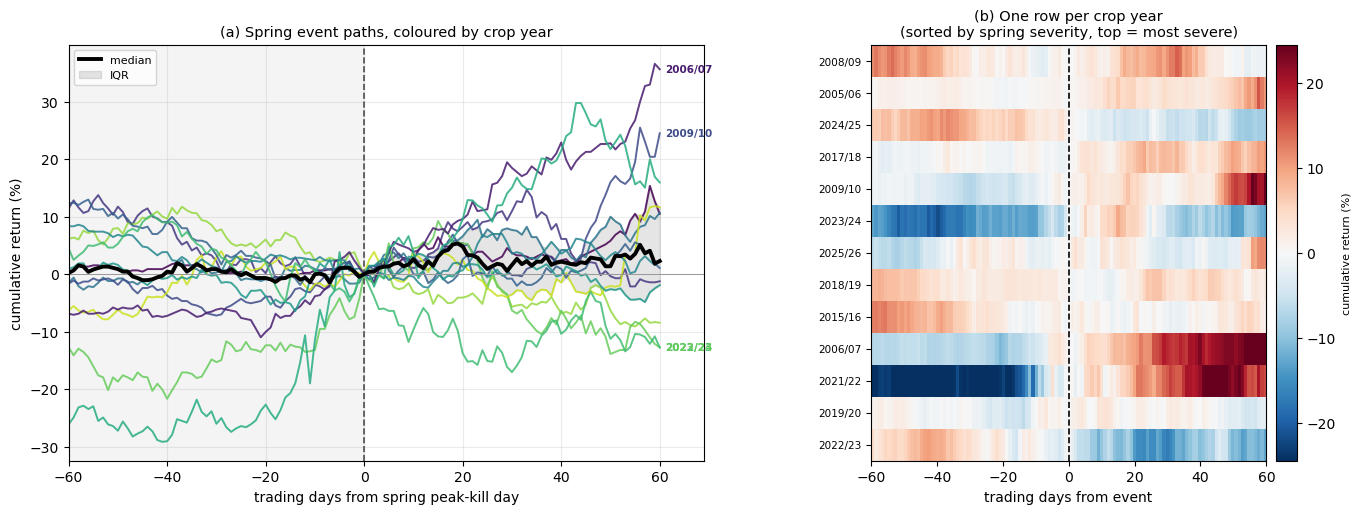

In [23]:
# --- Spring event paths, 60 trading days either side ------------------------------
PRE_P, POST_P = 60, 60
paths = {}
for d0, r in spv.iterrows():
    if r.frost_season not in S.index: continue
    c = df[df.symbol == r.symbol]; i = c.index.get_loc(d0)
    if i - PRE_P < 0: continue
    ret = c["ret"].values
    hi  = min(i + POST_P, len(c) - 1)
    rel = np.arange(i - PRE_P, hi + 1) - i
    post = np.concatenate([[0.0], np.nancumsum(ret[i+1:hi+1])]) * 100
    pre_ = -np.nancumsum(ret[i:i-PRE_P:-1])[::-1] * 100
    paths[r.frost_season] = pd.Series(np.concatenate([pre_, post]), index=rel)

Q = pd.DataFrame(paths)
Q = Q[[s for s in S.severity.sort_values(ascending=False).index if s in Q.columns]]

fig = plt.figure(figsize=(16.5, 5.4))
gs  = fig.add_gridspec(1, 2, width_ratios=[2, 1.5], wspace=.30)

ax  = fig.add_subplot(gs[0])
yrs = sorted(Q.columns, key=lambda s: int(s[:4]))
col = dict(zip(yrs, plt.cm.viridis(np.linspace(0, .92, len(yrs)))))
for s in Q.columns:
    ax.plot(Q.index, Q[s], color=col[s], lw=1.4, alpha=.85)
ax.plot(Q.index, Q.median(axis=1), color="k", lw=2.8, label="median", zorder=6)
ax.fill_between(Q.index, Q.quantile(.25, axis=1), Q.quantile(.75, axis=1),
                color="k", alpha=.10, label="IQR", zorder=1)
end = Q.iloc[-1].dropna().sort_values()
for s in list(end.index[:2]) + list(end.index[-2:]):
    ax.annotate(s, (Q.index[-1], end[s]), fontsize=7.5, color=col[s], weight="bold",
                xytext=(4, 0), textcoords="offset points", va="center")
ax.axvline(0, color="0.3", lw=1.2, ls="--"); ax.axhline(0, color="0.6", lw=.7)
ax.axvspan(-PRE_P, 0, color="0.955"); ax.set_xlim(-PRE_P, POST_P + 9)
ax.set_xlabel("trading days from spring peak-kill day")
ax.set_ylabel("cumulative return (%)")
ax.set_title("(a) Spring event paths, coloured by crop year", fontsize=10.5)
ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=.25)

ax = fig.add_subplot(gs[1]); M = Q.T
v  = np.nanpercentile(np.abs(M.values), 97)
im = ax.imshow(M.values, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v,
               extent=[Q.index[0], Q.index[-1], len(M), 0], interpolation="nearest")
ax.set_yticks(np.arange(len(M)) + .5); ax.set_yticklabels(M.index, fontsize=7.5)
ax.axvline(0, color="k", lw=1.2, ls="--"); ax.grid(False)
ax.set_xlabel("trading days from event")
ax.set_title("(b) One row per crop year\n(sorted by spring severity, top = most severe)",
             fontsize=10.5)
cb = fig.colorbar(im, ax=ax, pad=.02); cb.set_label("cumulative return (%)", fontsize=8)
fig.tight_layout()
for e in ("pdf", "png"):
    fig.savefig(FIGDIR/f"robustness_spring_event_study.{e}", dpi=200, bbox_inches="tight")
plt.show()

In [24]:
# --- Pre-event momentum around spring events --------------------------------------
pre  = -Q.loc[-40]          # return from h=-40 to the event
post =  Q.loc[ 40]          # return from the event to h=+40
c = pd.DataFrame({"pre40": pre, "post40": post}).dropna()
rho, p = stats.spearmanr(c.pre40, c.post40)
r,  pp = stats.pearsonr(c.pre40, c.post40)
print(c.round(2).sort_values("pre40").to_string())
print(f"\nSpearman {rho:+.2f} (p={p:.3f})   Pearson {r:+.2f} (p={pp:.3f})   n={len(c)}")

for k in (10, 20, 40):
    a, b = -Q.loc[-k], Q.loc[k]
    m = pd.DataFrame({"a": a, "b": b}).dropna()
    rr, ppp = stats.spearmanr(m.a, m.b)
    print(f"pre {k}d vs post {k}d: rho {rr:+.2f}  p {ppp:.3f}")

         pre40  post40
2024/25  -9.62   -6.80
2015/16  -9.11    0.92
2008/09  -9.05    6.12
2022/23  -8.96  -10.38
2018/19  -3.83    3.55
2005/06  -1.32    2.40
2017/18  -0.44    4.20
2019/20   0.68   -0.14
2025/26   3.16   -1.45
2009/10   3.72    2.17
2006/07   7.24   22.89
2023/24  21.65   -6.31
2021/22  29.02   21.42

Spearman +0.32 (p=0.289)   Pearson +0.47 (p=0.102)   n=13
pre 10d vs post 10d: rho +0.80  p 0.001
pre 20d vs post 20d: rho +0.68  p 0.011
pre 40d vs post 40d: rho +0.32  p 0.289


In [25]:
# --- Spring peak days in the panel LP with 5, 10 and 20 lag controls --------------
gp = df.groupby("symbol", sort=False)["logp"]
d  = df.copy()
d.loc[~d.index.month.isin([3,4,5]), "shock"] = np.nan
d.loc[(df.kill_incr > 0) & df.index.month.isin([3,4,5])
      & ~d.index.isin(pd.to_datetime(S.date)), "shock"] = np.nan   # peak days only

for L in (5, 10, 20):
    t = run_panel_lp(d, window=False, month_fe=False, lags=L)
    b, lo, hi = t.beta[20], t.lo[20], t.hi[20]
    pre = t[(t.index < 0) & (~t.degenerate)].beta.abs().max()
    print(f"lags={L:>2}  beta(20) {b:+.2f}%  [{lo:+.2f}, {hi:+.2f}]  placebo {pre:.2f}%")

lags= 5  beta(20) +2.76%  [-0.42, +5.94]  placebo 2.38%


lags=10  beta(20) +2.67%  [-0.63, +5.96]  placebo 0.83%


lags=20  beta(20) +2.78%  [-0.51, +6.07]  placebo nan%

In [26]:
# --- Spring sign test: leave one winter out, then vary the horizon ----------------
# leave-one-out on the sign count and the median
x = S.CAR20.dropna()
for s in x.index:
    z = x.drop(s)
    print(f"drop {s}: {int((z>0).sum())}/{len(z)} positive, median {z.median():+.2f}%")

# horizon robustness
for H in (10, 15, 20, 25, 30, 40):
    r = []
    for d0, rr in spv.iterrows():
        c = df[df.symbol == rr.symbol]; i = c.index.get_loc(d0)
        if i - 9 < 0 or i + H >= len(c): continue
        r.append(float(np.nansum(c["ret"].values[i:i+H+1]) * 100))
    r = np.array(r); k = int((r > 0).sum())
    print(f"h={H:>2}: n={len(r)}  median {np.median(r):+.2f}%  {k}/{len(r)} positive  "
          f"sign p={stats.binomtest(k, len(r), .5).pvalue:.3f}")

drop 2005/06: 10/12 positive, median +4.37%
drop 2006/07: 10/12 positive, median +4.37%
drop 2008/09: 10/12 positive, median +4.37%
drop 2009/10: 10/12 positive, median +4.40%
drop 2015/16: 10/12 positive, median +5.57%
drop 2017/18: 10/12 positive, median +4.37%
drop 2018/19: 10/12 positive, median +5.57%
drop 2019/20: 10/12 positive, median +5.57%
drop 2021/22: 10/12 positive, median +4.37%
drop 2022/23: 11/12 positive, median +5.57%
drop 2023/24: 10/12 positive, median +4.37%
drop 2024/25: 11/12 positive, median +5.57%
drop 2025/26: 10/12 positive, median +5.57%
h=10: n=13  median +2.84%  10/13 positive  sign p=0.092
h=15: n=13  median +3.56%  10/13 positive  sign p=0.092
h=20: n=13  median +5.54%  11/13 positive  sign p=0.022
h=25: n=13  median +1.69%  9/13 positive  sign p=0.267
h=30: n=13  median +2.15%  8/13 positive  sign p=0.581
h=40: n=13  median +2.55%  9/13 positive  sign p=0.267


In [27]:
# --- Spring LP: same estimator as paper Figure 4, March to May only ---------------
SPRING = [3, 4, 5]

d = df.copy()
d.loc[~d.index.month.isin(SPRING), "shock"] = np.nan     # non-spring rows leave the sample

n_fire = int((d.shock > 0).sum())
n_wint = int(d.loc[d.shock > 0, "frost_season"].nunique())
print(f"spring firing days {n_fire} across {n_wint} crop years")

irf_spring = run_panel_lp(d, window=False, month_fe=False)
r_spring   = report(irf_spring, "spring only (Mar-May)")

print("\nhorizon profile")
for h in (5, 10, 15, 18, 20, 25, 30):
    if h in irf_spring.index:
        b, lo, hi, se = (irf_spring.beta[h], irf_spring.lo[h],
                         irf_spring.hi[h], irf_spring.se[h])
        p = 2*(1-stats.norm.cdf(abs(b/se)))
        print(f"  h={h:>2}  {b:+.2f}%  [{lo:+.2f}, {hi:+.2f}]  p={p:.3f}")

# does HAC still behave at this sample size?
H = 20
gp   = df.groupby("symbol", sort=False)["logp"]
ctrl = pd.concat({f"rl{k}": df.groupby("symbol", sort=False)["ret"].shift(k)
                  for k in range(1, LAGS+1)}, axis=1)
y = ((gp.shift(-H) - gp.shift(1)) * 100).rename("y")
X = pd.concat([y, d.shock.rename("s"), ctrl], axis=1).dropna()
M = sm.OLS(X.y, sm.add_constant(X[["s"] + list(ctrl.columns)]))
o, hc = M.fit(), M.fit(cov_type="HAC", cov_kwds={"maxlags": H+5})
print(f"\ntreated {int(X.s.sum())}  OLS SE {o.bse['s']:.3f}  HAC SE {hc.bse['s']:.3f}  "
      f"ratio {hc.bse['s']/o.bse['s']:.2f}")

spring firing days 49 across 13 crop years
[spring only (Mar-May)] n=1321
  peak         -1.04% at h=30 (p=0.49)
  h=20         +0.14% [-2.07,+2.34]
  pointwise    min p = 0.489
  SIMULTANEOUS NOT significant
  MDE          +/-2.66%
  placebo max  0.89%

horizon profile
  h= 5  +0.33%  [-0.79, +1.46]  p=0.558
  h=10  -0.03%  [-1.49, +1.43]  p=0.967
  h=15  +0.51%  [-1.29, +2.30]  p=0.580
  h=18  +0.66%  [-1.40, +2.71]  p=0.531
  h=20  +0.14%  [-2.07, +2.34]  p=0.902
  h=25  -0.21%  [-2.99, +2.57]  p=0.882
  h=30  -1.04%  [-3.97, +1.90]  p=0.489

treated 49  OLS SE 0.924  HAC SE 1.125  ratio 1.22


In [28]:
# --- Spring LP: the 13 peak days vs the other spring firing days ------------------
SPRING = [3, 4, 5]
FIRE_S = (df.kill_incr > 0) & df.index.month.isin(SPRING)
peaks  = set(pd.to_datetime(S.date))          # the 13 spring peak days

for lab, keep in [("peak days only (13)", peaks),
                  ("non-peak spring days (36)", set(df.index[FIRE_S]) - peaks)]:
    d = df.copy()
    d.loc[~d.index.month.isin(SPRING), "shock"] = np.nan
    d.loc[FIRE_S & ~d.index.isin(keep), "shock"] = np.nan
    print(f"\n=== {lab}: {int((d.shock > 0).sum())} treated ===")
    report(run_panel_lp(d, window=False, month_fe=False), lab)

# how lopsided is the day weighting?
sp = df.loc[FIRE_S]
w  = sp.groupby("frost_season").size().rename("spring_days").to_frame()
w["CAR20"] = S.CAR20.reindex(w.index)
w["weight"] = (w.spring_days / w.spring_days.sum()).round(3)
print("\n" + w.sort_values("spring_days", ascending=False).to_string())
print(f"\nday-weighted mean CAR20  {(w.CAR20 * w.spring_days).sum() / w.spring_days.sum():+.2f}%")
print(f"year-weighted mean CAR20 {w.CAR20.mean():+.2f}%")


=== peak days only (13): 13 treated ===


[peak days only (13)] n=1285
  peak         +2.99% at h=21 (p=0.10)
  h=20         +2.76% [-0.42,+5.94]
  pointwise    min p = 0.060
  SIMULTANEOUS NOT significant
  MDE          +/-3.78%
  placebo max  2.38%

=== non-peak spring days (36): 36 treated ===


[non-peak spring days (36)] n=1308
  peak         -1.95% at h=30 (p=0.20)
  h=20         -0.80% [-3.11,+1.52]
  pointwise    min p = 0.200
  SIMULTANEOUS NOT significant
  MDE          +/-2.72%
  placebo max  0.48%

              spring_days      CAR20  weight
frost_season                                
2025/26                12   2.361385   0.245
2008/09                 7   8.246891   0.143
2024/25                 7  -5.817664   0.143
2019/20                 5   1.215410   0.102
2015/16                 3   3.199054   0.061
2017/18                 3   8.073547   0.061
2005/06                 2   5.604915   0.041
2009/10                 2   5.542079   0.041
2021/22                 2  10.048755   0.041
2022/23                 2 -12.783337   0.041
2023/24                 2   9.627683   0.041
2006/07                 1   8.392018   0.020
2018/19                 1   0.286123   0.020

day-weighted mean CAR20  +2.65%
year-weighted mean CAR20 +3.38%


In [29]:
# --- Spring events by month, and the smallest attainable sign-test p --------------
SPRING = [3, 4, 5]
m = S.copy()
m["mon"] = pd.to_datetime(m.date).dt.month

print(m.groupby("mon").agg(events=("CAR20","size"), mean=("CAR20","mean"),
                           median=("CAR20","median"),
                           pos=("CAR20", lambda x: f"{int((x>0).sum())}/{len(x)}"),
                           sev=("severity","mean")).round(3).to_string())

sp = df.loc[(df.kill_incr > 0) & df.index.month.isin(SPRING)]
print("\nall 49 spring firing days by month:")
print(sp.groupby(sp.index.month)["kill_incr"].agg(days="size", mean="mean",
                                                  max="max").round(4).to_string())

for n in (3,4,5,6,7):
    print(f"n={n}: smallest possible sign-test p = {stats.binomtest(n,n,0.5).pvalue:.3f}")

     events   mean  median  pos    sev
mon                                   
3         2  6.624   6.624  2/2  0.009
4         8  0.891   1.788  6/8  0.034
5         3  7.875   8.392  3/3  0.035

all 49 spring firing days by month:
      days    mean     max
date                      
3       15  0.0066  0.0191
4       28  0.0190  0.0913
5        6  0.0228  0.0738
n=3: smallest possible sign-test p = 0.250
n=4: smallest possible sign-test p = 0.125
n=5: smallest possible sign-test p = 0.062
n=6: smallest possible sign-test p = 0.031
n=7: smallest possible sign-test p = 0.016


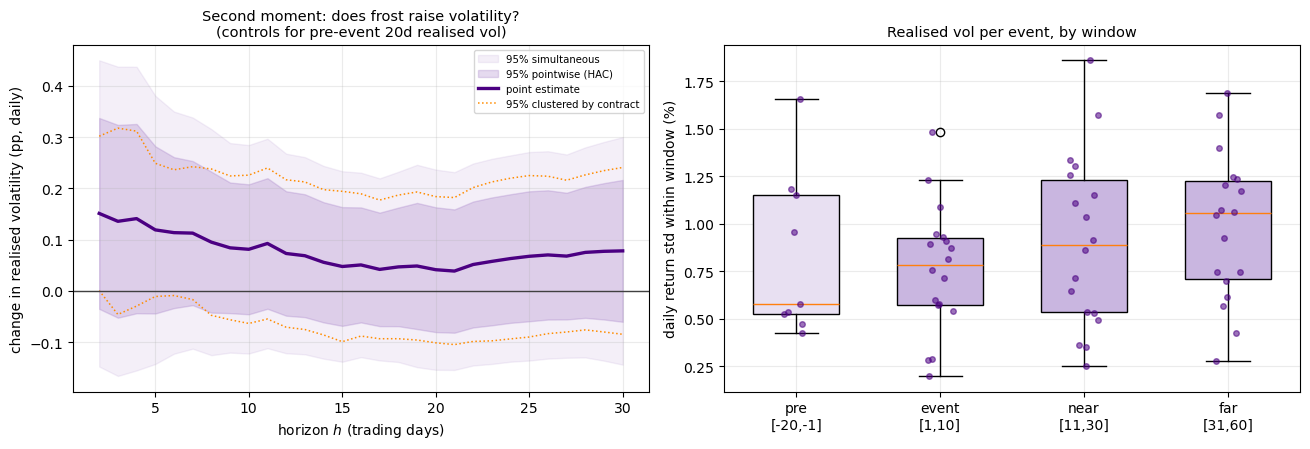

vol LP peak +0.151 pp at h=2
  HAC min p 0.112 | clustered min p 0.049
  simultaneous: HAC False, clustered False
  median vol pre 0.58% -> event 0.78% (Wilcoxon p=1.000)


In [30]:
# --- Volatility response: does frost raise realised volatility? -------------------
def run_vol_lp(d, shock="shock", h_fwd=30, alpha=ALPHA, cluster=False, window=True):
    gr = d.groupby("symbol", sort=False)["ret"]
    rv_pre = gr.transform(lambda s: s.rolling(20, min_periods=10).std()) * 100
    z_pt = stats.norm.ppf(1-alpha/2); z_sim = stats.norm.ppf(1-alpha/(2*h_fwd))
    rows = []
    for h in range(2, h_fwd+1):
        mp = min(max(2, h//2), h)
        fwd = gr.transform(lambda s, h=h, mp=mp:
                s[::-1].rolling(h, min_periods=mp).std()[::-1].shift(-1)) * 100
        X = pd.concat([fwd.rename("y"), d[shock].rename("s"),
                       rv_pre.rename("rv_pre"), d["symbol"].rename("g")], axis=1).dropna()
        if window: X = X[X.index.month.isin(FROST_MONTHS)]
        if len(X) < 50 or X.s.std() == 0: continue
        M = sm.OLS(X.y, sm.add_constant(X[["s","rv_pre"]]))
        res = (M.fit(cov_type="cluster", cov_kwds={"groups": X.g}) if cluster
               else M.fit(cov_type="HAC", cov_kwds={"maxlags": h+5}))
        b, se = res.params["s"], res.bse["s"]
        rows.append(dict(h=h, beta=b, se=se, lo=b-z_pt*se, hi=b+z_pt*se,
                         lo_s=b-z_sim*se, hi_s=b+z_sim*se, n=len(X)))
    return pd.DataFrame(rows).set_index("h")

irf_vol, irf_vol_cl = run_vol_lp(df), run_vol_lp(df, cluster=True)

WIN = {"pre\n[-20,-1]": (-20,-1), "event\n[1,10]": (1,10),
       "near\n[11,30]": (11,30), "far\n[31,60]": (31,60)}
vals = {k: [] for k in WIN}
for d0, r in ev.iterrows():
    c = df[df.symbol == r.symbol]; i = c.index.get_loc(d0); ret = c["ret"].values
    for k,(a,b) in WIN.items():
        lo, hi = i+a, i+b+1
        if lo < 0 or hi > len(ret): continue
        seg = ret[lo:hi]
        if np.isfinite(seg).sum() > 3: vals[k].append(np.nanstd(seg)*100)

fig, ax = plt.subplots(1, 2, figsize=(13.2, 4.6))
t, tc = irf_vol, irf_vol_cl
ax[0].fill_between(t.index, t.lo_s, t.hi_s, color="tab:purple", alpha=.10, label="95% simultaneous")
ax[0].fill_between(t.index, t.lo, t.hi, color="tab:purple", alpha=.24, label="95% pointwise (HAC)")
ax[0].plot(t.index, t.beta, color="indigo", lw=2.4, label="point estimate")
ax[0].plot(tc.index, tc.lo, color="darkorange", lw=1.1, ls=":")
ax[0].plot(tc.index, tc.hi, color="darkorange", lw=1.1, ls=":", label="95% clustered by contract")
ax[0].axhline(0, color="0.25", lw=1)
ax[0].set_xlabel("horizon $h$ (trading days)")
ax[0].set_ylabel("change in realised volatility (pp, daily)")
ax[0].set_title("Second moment: does frost raise volatility?\n(controls for pre-event 20d realised vol)", fontsize=10.5)
ax[0].legend(fontsize=7.3, loc="upper right"); ax[0].grid(alpha=.25)

bp = ax[1].boxplot([vals[k] for k in WIN], patch_artist=True, widths=.6)
ax[1].set_xticks(range(1, len(WIN) + 1)); ax[1].set_xticklabels(list(WIN))
for i, b_ in enumerate(bp["boxes"]): b_.set_facecolor("#e8e0f2" if i == 0 else "#c9b6e0")
for k in WIN:
    x = list(WIN).index(k) + 1
    ax[1].scatter(np.full(len(vals[k]), x) + np.random.uniform(-.10,.10,len(vals[k])),
                  vals[k], s=16, c="indigo", alpha=.55, zorder=4)
ax[1].set_ylabel("daily return std within window (%)")
ax[1].set_title("Realised vol per event, by window", fontsize=10.5); ax[1].grid(alpha=.25, axis="y")
fig.tight_layout()
for e in ("pdf","png"):
    fig.savefig(FIGDIR/f"robustness_volatility.{e}", dpi=200, bbox_inches="tight")
plt.show()

pv  = pd.Series(2*(1-stats.norm.cdf((t.beta/t.se).abs())), index=t.index)
pvc = pd.Series(2*(1-stats.norm.cdf((tc.beta/tc.se).abs())), index=tc.index)
print(f"vol LP peak {t.beta[t.beta.abs().idxmax()]:+.3f} pp at h={t.beta.abs().idxmax()}")
print(f"  HAC min p {pv.min():.3f} | clustered min p {pvc.min():.3f}")
print(f"  simultaneous: HAC {bool(((t.lo_s>0)|(t.hi_s<0)).any())}, "
      f"clustered {bool(((tc.lo_s>0)|(tc.hi_s<0)).any())}")
a_, b_ = vals[list(WIN)[0]], vals[list(WIN)[1]]
if len(a_) and len(b_):
    n = min(len(a_), len(b_))
    print(f"  median vol pre {np.median(a_):.2f}% -> event {np.median(b_):.2f}% "
          f"(Wilcoxon p={stats.wilcoxon(a_[:n], b_[:n]).pvalue:.3f})")

firing days: 113 | rank range 1.000
raw severity deciles:
count    113.0000
mean       0.0289
std        0.0460
min        0.0003
10%        0.0012
25%        0.0029
50%        0.0091
75%        0.0320
90%        0.0776
99%        0.2182
max        0.2444
[new-crop, rank-graded] n=4142
  peak         +1.64% at h=18 (p=0.09)
  h=20         +1.43% [-0.59,+3.44]
  pointwise    min p = 0.070
  SIMULTANEOUS NOT significant
  MDE          +/-2.43%
  placebo max  0.80%


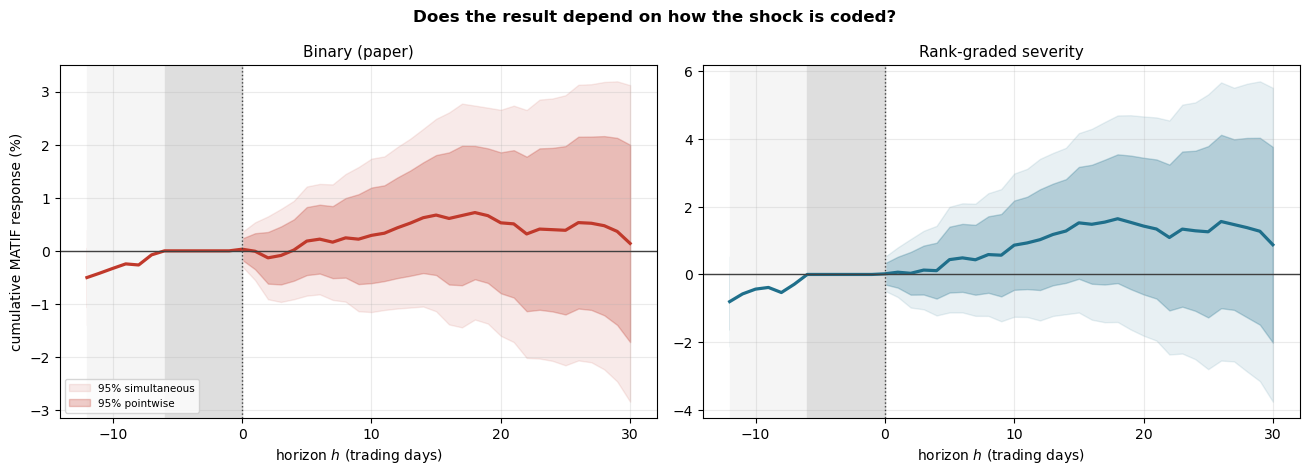


binary  h=20: +0.53%  [-0.80,+1.85]
rank    h=20: +1.43%  [-0.59,+3.44]

Rank beta is the response moving from the mildest to the most severe
frost day, so it is NOT directly comparable in magnitude to the binary.


In [31]:
# --- Rank-graded shock: does coding severity change the result? -------------------
# Raw kill_incr is heavy-tailed (median about 0.01, maximum about 0.24), so a handful
# of days would set an OLS slope. The percentile rank keeps the ordering the signal
# delivers and removes that leverage. It also matches how FROSTOL output is read here,
# as a ranking within one location rather than a literal kill percentage.

nz = df.loc[df.kill_incr > 0, "kill_incr"]
df["shock_rank"] = 0.0
df.loc[nz.index, "shock_rank"] = nz.rank(pct=True)      # 0-1 across firing days
df.loc[df.kill_incr.isna(), "shock_rank"] = np.nan

print(f"firing days: {len(nz)} | rank range {df.shock_rank.max():.3f}")
print("raw severity deciles:")
print(nz.describe(percentiles=[.1,.25,.5,.75,.9,.99]).round(4).to_string())

irf_rank = run_panel_lp(df, shock="shock_rank", window=False, month_fe=False)
r_rank = report(irf_rank, "new-crop, rank-graded")

# side-by-side with the binary baseline
fig, ax = plt.subplots(1, 2, figsize=(13.2, 4.8), sharex=True)
for a, (t, ttl, c) in zip(ax, [
        (irf_nc,   "Binary (paper)",        "#c0392b"),
        (irf_rank, "Rank-graded severity",  "#1f6f8b")]):
    a.fill_between(t.index, t.lo_s, t.hi_s, color=c, alpha=.10, label="95% simultaneous")
    a.fill_between(t.index, t.lo,   t.hi,   color=c, alpha=.26, label="95% pointwise")
    a.plot(t.index, t.beta, color=c, lw=2.3)
    a.axhline(0, color="0.25", lw=1); a.axvline(0, color="0.25", lw=1, ls=":")
    a.axvspan(t.index.min(), 0, color="0.96")
    deg = t[t.degenerate]
    if len(deg): a.axvspan(deg.index.min(), 0, color="0.87")
    a.set_xlabel("horizon $h$ (trading days)"); a.set_title(ttl, fontsize=11)
    a.grid(alpha=.25)
ax[0].set_ylabel("cumulative MATIF response (%)")
ax[0].legend(fontsize=7.5, loc="lower left")
fig.suptitle("Does the result depend on how the shock is coded?",
             fontsize=12, weight="bold")
fig.tight_layout()
for e in ("pdf","png"):
    fig.savefig(FIGDIR/f"robustness_shock_coding.{e}", dpi=200, bbox_inches="tight")
plt.show()

# scale note: binary beta = frost day vs none; rank beta = mildest -> most severe
print(f"\nbinary  h=20: {irf_nc.beta[20]:+.2f}%  [{irf_nc.lo[20]:+.2f},{irf_nc.hi[20]:+.2f}]")
print(f"rank    h=20: {irf_rank.beta[20]:+.2f}%  [{irf_rank.lo[20]:+.2f},{irf_rank.hi[20]:+.2f}]")
print("\nRank beta is the response moving from the mildest to the most severe")
print("frost day, so it is NOT directly comparable in magnitude to the binary.")

In [32]:
# --- Check the rank mapping at both ends ------------------------------------------
chk = df.loc[df.kill_incr > 0, ["kill_incr", "shock_rank"]].sort_values("kill_incr")
print(chk.head(3).round(4)); print(chk.tail(3).round(4))

            kill_incr  shock_rank
date                             
2015-10-16     0.0003      0.0088
2026-03-10     0.0005      0.0177
2013-10-22     0.0005      0.0265
            kill_incr  shock_rank
date                             
2009-10-28     0.1804      0.9823
2007-02-26     0.2234      0.9912
2019-11-01     0.2444      1.0000


In [33]:
# --- Firing days by month ---------------------------------------------------------
fire = (df.kill_incr > 0) & df.index.month.isin(FROST_MONTHS)
print("kill_incr > 0, any month :", int((df.kill_incr > 0).sum()))
print("kill_incr > 0, in window :", int(fire.sum()))
print("shock > 0, any month     :", int((df.shock > 0).sum()))
print("\nfiring days by month:")
print(df.loc[df.kill_incr > 0].index.month.value_counts().sort_index().to_string())

kill_incr > 0, any month : 113
kill_incr > 0, in window : 74
shock > 0, any month     : 113

firing days by month:
date
1     10
2     12
3     15
4     28
5      6
10    33
11     8
12     1


firing days: 113 across 18 crop years

      all: cut=0.0000  n=113  (expect ~113)  years=18
  top 50%: cut=0.0091  n= 57  (expect ~56)  years=16


  top 25%: cut=0.0320  n= 29  (expect ~28)  years=13
  top 10%: cut=0.0776  n= 12  (expect ~11)  years=8



 subset   cut  n_days  n_years   b20   lo20  hi20  peak  peak_h  min_p   sim   mde  placebo
    all 0.000     113       18 0.528 -0.799 1.855 0.721      18  0.241 False 1.696    0.503
top 50% 0.009      57       16 0.668 -0.880 2.217 1.017      26  0.200 False 2.001    0.551
top 25% 0.032      29       13 1.007 -0.625 2.638 1.314      29  0.146 False 1.968    0.375
top 10% 0.078      12        8 1.648 -0.077 3.372 2.426      30  0.028 False 1.813    0.480

n_years is the effective sample size, since kill fires on consecutive days in one cold snap.


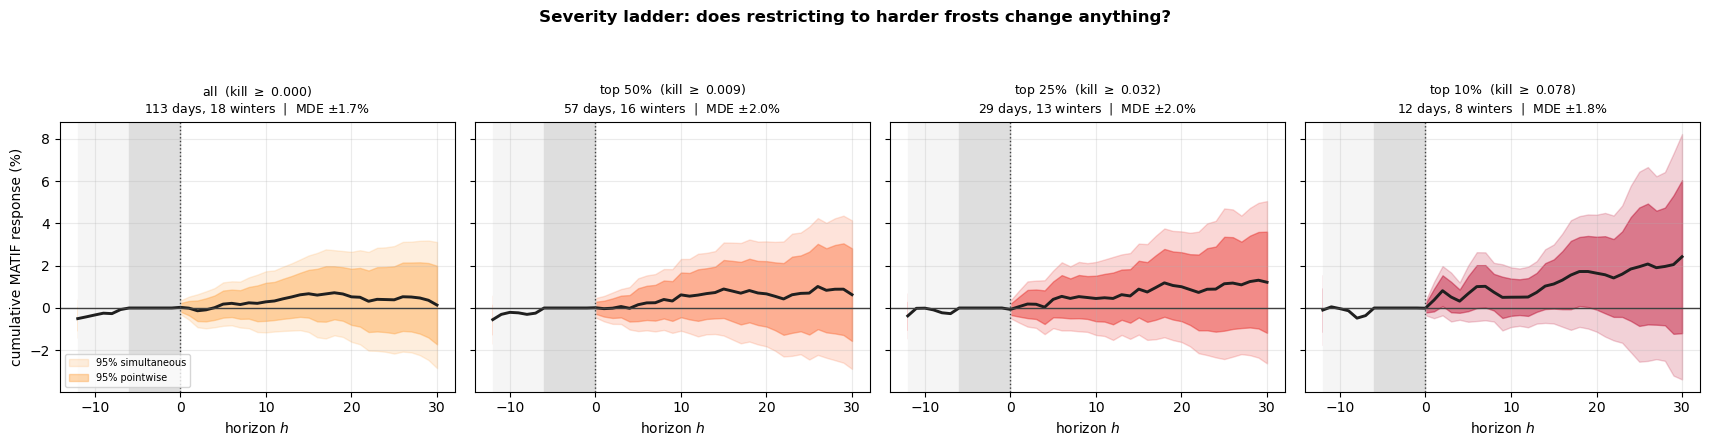

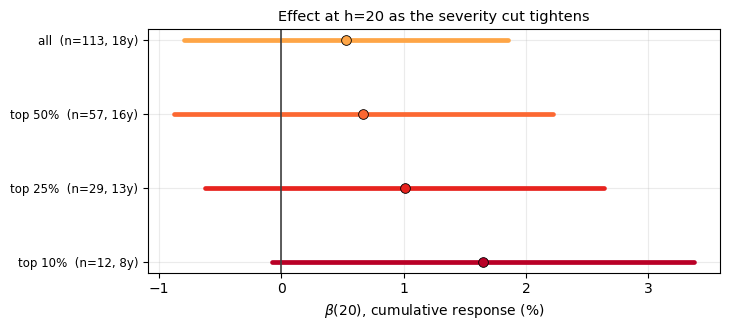

In [34]:
# --- Severity ladder: all firing days, then the top 50%, 25% and 10% --------------
# Firing days below the cut leave the sample (shock set to NaN) rather than being
# recoded to 0, so the comparison group stays non-frost days throughout.

FIRE = df.kill_incr > 0
n_fire = int(FIRE.sum())
print(f"firing days: {n_fire} across "
      f"{df.loc[FIRE, 'frost_season'].nunique()} crop years\n")

THRESH = [(0.00, "all"), (0.50, "top 50%"), (0.75, "top 25%"), (0.90, "top 10%")]

lad, tabs = [], {}
for q, lab in THRESH:
    d = df.copy()
    cut = d.loc[FIRE, "kill_incr"].quantile(q) if q > 0 else 0.0
    if q > 0:
        d.loc[(d.kill_incr > 0) & (d.kill_incr < cut), "shock"] = np.nan
    kept = d.loc[d.shock > 0]
    print(f"{lab:>9}: cut={cut:.4f}  n={len(kept):>3}  "
          f"(expect ~{(1-q)*n_fire:.0f})  years={kept.frost_season.nunique()}")
    if len(kept) < 5:
        print(f"           -> too few, skipped"); continue
    t = run_panel_lp(d, shock="shock", window=False, month_fe=False)
    tabs[lab] = t
    fwd = t[t.index > 0]
    pv = pd.Series(2*(1-stats.norm.cdf((t.beta/t.se.replace(0, np.nan)).abs())),
                   index=t.index)
    lad.append(dict(subset=lab, cut=cut, n_days=len(kept),
                    n_years=kept.frost_season.nunique(),
                    b20=t.beta.get(20, np.nan), lo20=t.lo.get(20, np.nan),
                    hi20=t.hi.get(20, np.nan),
                    peak=t.beta[t.beta.abs().idxmax()],
                    peak_h=t.beta.abs().idxmax(),
                    min_p=pv[fwd.index].min(),
                    sim=bool(((fwd.lo_s > 0) | (fwd.hi_s < 0)).any()),
                    mde=(1.96+0.84)*float(fwd.se.median()),
                    placebo=t.loc[(t.index < 0) & (~t.degenerate), "beta"].abs().max()))

L = pd.DataFrame(lad)
print("\n" + L.round(3).to_string(index=False))
print("\nn_years is the effective sample size, since kill fires on consecutive days in one cold snap.")

# ---- plot -------------------------------------------------------------------
fig, ax = plt.subplots(1, len(tabs), figsize=(4.3*len(tabs), 4.5),
                       sharex=True, sharey=True)
ax = np.atleast_1d(ax)
pal = plt.cm.YlOrRd(np.linspace(.42, .88, len(tabs)))
for a, (lab, t), c in zip(ax, tabs.items(), pal):
    a.fill_between(t.index, t.lo_s, t.hi_s, color=c, alpha=.18, label="95% simultaneous")
    a.fill_between(t.index, t.lo,   t.hi,   color=c, alpha=.42, label="95% pointwise")
    a.plot(t.index, t.beta, color="0.12", lw=2.1)
    a.axhline(0, color="0.25", lw=1); a.axvline(0, color="0.25", lw=1, ls=":")
    a.axvspan(t.index.min(), 0, color="0.96")
    deg = t[t.degenerate]
    if len(deg): a.axvspan(deg.index.min(), 0, color="0.87")
    r = L[L.subset == lab].iloc[0]
    a.set_title(f"{lab}  (kill $\\geq$ {r.cut:.3f})\n"
                f"{int(r.n_days)} days, {int(r.n_years)} winters"
                f"  |  MDE $\\pm${r.mde:.1f}%", fontsize=9)
    a.set_xlabel("horizon $h$"); a.grid(alpha=.25)
ax[0].set_ylabel("cumulative MATIF response (%)")
ax[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Severity ladder: does restricting to harder frosts change anything?",
             fontsize=12, weight="bold")
fig.tight_layout(rect=[0, 0, 1, .92])
for e in ("pdf", "png"):
    fig.savefig(FIGDIR/f"robustness_severity_ladder.{e}", dpi=200, bbox_inches="tight")
plt.show()

# ---- forest of beta(20) across rungs ----------------------------------------
fig, a = plt.subplots(figsize=(7.4, 3.4))
y = np.arange(len(L))
for i, r in L.iterrows():
    a.plot([r.lo20, r.hi20], [i, i], lw=3.4, color=pal[i], solid_capstyle="round")
    a.plot(r.b20, i, "o", ms=7, color=pal[i], mec="k", mew=.6, zorder=5)
a.axvline(0, color="0.25", lw=1.2)
a.set_yticks(y)
a.set_yticklabels([f"{r.subset}  (n={int(r.n_days)}, {int(r.n_years)}y)"
                   for _, r in L.iterrows()], fontsize=8.5)
a.invert_yaxis(); a.set_xlabel(r"$\beta(20)$, cumulative response (%)")
a.set_title("Effect at h=20 as the severity cut tightens", fontsize=10.5)
a.grid(alpha=.25, axis="x")
fig.tight_layout()
for e in ("pdf", "png"):
    fig.savefig(FIGDIR/f"robustness_ladder_forest.{e}", dpi=200, bbox_inches="tight")
plt.show()
L.to_csv(OUT/"lp_severity_ladder.csv", index=False)

In [35]:
# --- Standard errors across ladder rungs ------------------------------------------
for lab, t in tabs.items():
    fwd = t[t.index > 0]
    print(f"{lab:>9}  median SE {fwd.se.median():.3f}  min {fwd.se.min():.3f}  max {fwd.se.max():.3f}")

      all  median SE 0.606  min 0.173  max 0.948
  top 50%  median SE 0.715  min 0.191  max 1.118
  top 25%  median SE 0.703  min 0.240  max 1.221
  top 10%  median SE 0.648  min 0.273  max 1.847


In [36]:
# --- OLS, HAC and contract-clustered standard errors at h = 20 --------------------
H, FIRE = 20, df.kill_incr > 0
gp   = df.groupby("symbol", sort=False)["logp"]
y    = ((gp.shift(-H) - gp.shift(1)) * 100).rename("y")
ctrl = pd.concat({f"rl{k}": df.groupby("symbol", sort=False)["ret"].shift(k)
                  for k in range(1, LAGS+1)}, axis=1)

for q, lab in [(0.00,"all"), (0.50,"top 50%"), (0.75,"top 25%"), (0.90,"top 10%")]:
    d = df.copy()
    cut = d.loc[FIRE, "kill_incr"].quantile(q) if q > 0 else 0.0
    if q > 0: d.loc[(d.kill_incr > 0) & (d.kill_incr < cut), "shock"] = np.nan
    X = pd.concat([y, d.shock.rename("s"), ctrl, d.symbol.rename("g")], axis=1).dropna()
    M = sm.OLS(X.y, sm.add_constant(X[["s"] + list(ctrl.columns)]))
    o, hc, cl = (M.fit(), M.fit(cov_type="HAC", cov_kwds={"maxlags": H+5}),
                 M.fit(cov_type="cluster", cov_kwds={"groups": X.g}))
    print(f"{lab:>9}  treated {int(X.s.sum()):>4}  OLS {o.bse['s']:.3f}  "
          f"HAC {hc.bse['s']:.3f}  cluster {cl.bse['s']:.3f}")

      all  treated  113  OLS 0.589  HAC 0.677  cluster 0.634
  top 50%  treated   57  OLS 0.824  HAC 0.790  cluster 0.883
  top 25%  treated   29  OLS 1.153  HAC 0.832  cluster 0.935
  top 10%  treated   12  OLS 1.790  HAC 0.880  cluster 1.038


In [37]:
# --- Ladder decomposition: which days and winters drive the upper rungs -----------
H = 20
gp = df.groupby("symbol", sort=False)["logp"]
y  = (gp.shift(-H) - gp.shift(1)) * 100.0

FIRE = (df.kill_incr > 0) & df.index.month.isin(FROST_MONTHS)
q = df.loc[FIRE, "kill_incr"].quantile([0.50, 0.75, 0.90])

band = pd.Series(index=df.index, dtype=object)
band[FIRE] = "bottom 50%"
band[FIRE & (df.kill_incr >= q[0.50])] = "50-75%"
band[FIRE & (df.kill_incr >= q[0.75])] = "75-90%"
band[FIRE & (df.kill_incr >= q[0.90])] = "top 10%"

E = pd.DataFrame({"season": df.frost_season, "month": df.index.month,
                  "kill": df.kill_incr, "band": band, "y20": y})[FIRE]

print(E.sort_values("kill", ascending=False).round(3).to_string())
print("\nby band")
print(E.groupby("band").agg(n=("kill","size"), winters=("season","nunique"),
                            mean_y=("y20","mean"), median_y=("y20","median")
                            ).round(2).to_string())
print("\ntop 25% by winter")
print(E[E.band.isin(["75-90%","top 10%"])]
        .groupby(["season","band"]).agg(n=("kill","size"), mean_y=("y20","mean")
        ).round(2).to_string())

             season  month   kill        band     y20
date                                                 
2019-11-01  2019/20     11  0.244     top 10%   0.691
2007-02-26  2006/07      2  0.223     top 10%  -0.544
2019-11-04  2019/20     11  0.128     top 10%   0.416
2009-04-14  2008/09      4  0.091     top 10%   8.247
2025-12-29  2025/26     12  0.078     top 10%  -1.287
2009-04-24  2008/09      4  0.075     top 10%   7.338
2025-04-10  2024/25      4  0.057     top 10%  -5.818
2007-02-28  2006/07      2  0.053     top 10%  -1.463
2007-02-23  2006/07      2  0.052      75-90%  -0.362
2025-04-14  2024/25      4  0.048      75-90%  -4.160
2006-11-06  2006/07     11  0.041      75-90%  -1.101
2018-04-25  2017/18      4  0.037      75-90%   8.074
2010-04-28  2009/10      4  0.034      75-90%   5.542
2006-01-19  2005/06      1  0.032      75-90%   2.667
2007-11-07  2007/08     11  0.030      75-90%   4.604
2025-04-30  2024/25      4  0.026      75-90%  -1.839
2009-04-23  2008/09      4  

In [38]:
# --- Event-level ladder: one treated day per cold snap ----------------------------
GAP = 10
FIRE = (df.kill_incr > 0) & df.index.month.isin(FROST_MONTHS)
f = df.loc[FIRE].sort_index()
eid = (f.index.to_series().diff().dt.days.fillna(999) > GAP).cumsum()
ev = f.assign(eid=eid).groupby("eid").agg(peak=("kill_incr","idxmax"),
                                          kmax=("kill_incr","max"),
                                          season=("frost_season","first"))
print(f"{len(ev)} events across {ev.season.nunique()} winters (from {int(FIRE.sum())} days)")

for q, lab in [(0.00,"all"), (0.50,"top 50%")]:          # stop at 50%, below that n<8
    cut = ev.kmax.quantile(q) if q > 0 else 0.0
    keep = set(ev.loc[ev.kmax >= cut, "peak"])
    d = df.copy()
    d.loc[FIRE & ~d.index.isin(keep), "shock"] = np.nan   # every non-peak day out
    sel = ev[ev.kmax >= cut]
    print(f"{lab}: {len(sel)} events, {sel.season.nunique()} winters")
    report(run_panel_lp(d, shock="shock"), lab)

32 events across 14 winters (from 74 days)
all: 32 events, 14 winters
[all] n=2585
  peak         -0.57% at h=9 (p=0.36)
  h=20         +0.01% [-1.81,+1.82]
  pointwise    min p = 0.317
  SIMULTANEOUS NOT significant
  MDE          +/-2.18%
  placebo max  0.28%
top 50%: 16 events, 11 winters


[top 50%] n=2569
  peak         +1.12% at h=26 (p=0.39)
  h=20         +0.60% [-1.49,+2.69]
  pointwise    min p = 0.366
  SIMULTANEOUS NOT significant
  MDE          +/-2.44%
  placebo max  0.17%


In [39]:
# --- Leave one winter out on the top-50% event rung -------------------------------
cut = ev.kmax.quantile(0.50)
sel = ev[ev.kmax >= cut]
keep_all = set(sel.peak)
rows = []
for w in [None] + sorted(sel.season.unique()):
    keep = keep_all - set(sel.loc[sel.season == w, "peak"]) if w else keep_all
    d = df.copy()
    d.loc[FIRE & ~d.index.isin(keep), "shock"] = np.nan
    t = run_panel_lp(d, shock="shock")
    rows.append(dict(dropped=w or "none", n_ev=len(keep),
                     b20=t.beta.get(20, np.nan), lo20=t.lo.get(20, np.nan),
                     hi20=t.hi.get(20, np.nan), b26=t.beta.get(26, np.nan)))
print(pd.DataFrame(rows).round(2).to_string(index=False))

dropped  n_ev  b20  lo20  hi20  b26
   none    16 0.60 -1.49  2.69 1.12
2005/06    15 0.49 -1.71  2.69 1.05
2006/07    14 0.85 -1.49  3.19 1.68
2007/08    15 0.36 -1.83  2.55 0.49
2008/09    15 0.12 -1.88  2.12 0.59
2009/10    15 0.30 -1.87  2.47 1.09
2010/11    14 0.79 -1.58  3.16 1.40
2017/18    15 0.11 -1.88  2.09 0.63
2018/19    15 0.62 -1.60  2.84 0.80
2019/20    15 0.60 -1.61  2.82 1.21
2024/25    14 1.27 -0.78  3.32 1.51
2025/26    13 1.30 -0.94  3.54 2.08
